# Лабораторна робота № 4
## Дерева рішень та ансамблеві методи в багатокласовій класифікації за наявності пропущених значень

**Виконав:** Новак Сергій, ФЕІ-43с 

**Номер у списку групи:** $N = 8$, отже $\text{SEED} = 42 + N = 50$

**Мета.** Порівняти Decision Tree, Random Forest і XGBoost на датасеті Annealing, дослідити вплив способу обробки пропусків, коректно (без витоку даних) підібрати гіперпараметри за допомогою Optuna, отримати неупереджену оцінку якості вкладеною крос-валідацією, статистично порівняти моделі тестом Наде–Бенжіо та інтерпретувати їх (MDI, permutation importance, SHAP).

**Дані.** OpenML `anneal`, версія 1 - **898 спостережень**, 38 ознак (не навчальна частина UCI на 798 об'єктів).

Усі джерела випадковості (поділ даних, крос-валідація, моделі, семплер Optuna, permutation importance) ініціалізуються однією константою `SEED`. Ноутбук розрахований на **Restart & Run All**; версії бібліотек зафіксовано в `requirements.txt` і виведено нижче.

In [1]:
import platform
import time
import warnings
from pathlib import Path
from urllib.parse import unquote

import joblib
import matplotlib
import matplotlib.patches
import matplotlib.pyplot as plt
import numpy as np
import optuna
import pandas as pd
import scipy
import seaborn as sns
import shap
import sklearn
import xgboost
from IPython.display import Markdown, display
from matplotlib.colors import LinearSegmentedColormap
from scipy import stats
from sklearn.compose import ColumnTransformer, make_column_selector
from sklearn.datasets import fetch_openml
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import MissingIndicator, SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    make_scorer,
)
from sklearn.model_selection import (
    RepeatedStratifiedKFold,
    StratifiedKFold,
    cross_val_predict,
    cross_val_score,
    cross_validate,
    train_test_split,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import LabelEncoder, OneHotEncoder
from sklearn.tree import DecisionTreeClassifier
from xgboost import XGBClassifier

STUDENT_N = 8
SEED = 42 + STUDENT_N
np.random.seed(SEED)

warnings.filterwarnings("ignore", message="Skipping features without any observed values")
warnings.filterwarnings("ignore", category=optuna.exceptions.ExperimentalWarning)
warnings.filterwarnings("ignore", category=FutureWarning)
optuna.logging.set_verbosity(optuna.logging.WARNING)

COLORS = {"blue": "#2a78d6", "orange": "#eb6834", "aqua": "#1baf7a", "muted": "#8a8984"}
MODEL_NAMES = ["DT", "RF", "XGB"]
MODEL_TITLES = {"DT": "Decision Tree", "RF": "Random Forest", "XGB": "XGBoost"}
MODEL_COLORS = {"DT": COLORS["blue"], "RF": COLORS["orange"], "XGB": COLORS["aqua"]}
BLUE_RAMP = LinearSegmentedColormap.from_list(
    "blue_ramp", ["#f4f8fd", "#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"]
)

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_colwidth", 200)
plt.rcParams.update({
    "figure.dpi": 110,
    "axes.edgecolor": "#c3c2b7",
    "grid.color": "#e6e5e0",
    "axes.titleweight": "bold",
})

MODELS_DIR = Path("models")
MODELS_DIR.mkdir(exist_ok=True)

versions = pd.Series({
    "Python": platform.python_version(),
    "scikit-learn": sklearn.__version__,
    "xgboost": xgboost.__version__,
    "optuna": optuna.__version__,
    "shap": shap.__version__,
    "numpy": np.__version__,
    "pandas": pd.__version__,
    "scipy": scipy.__version__,
    "matplotlib": matplotlib.__version__,
    "seaborn": sns.__version__,
}, name="версія")
print(f"SEED = 42 + {STUDENT_N} = {SEED}")
display(versions.to_frame())

SEED = 42 + 8 = 50


,версія
Python,3.12.11
scikit-learn,1.9.1
xgboost,3.4.1
optuna,5.0.0
shap,0.54.1
numpy,2.5.4
pandas,3.0.6
scipy,1.18.1
matplotlib,3.11.2
seaborn,0.13.2


## 3.1 Первинний аналіз даних

Завантажуємо датасет з OpenML і приводимо категоріальні ознаки до типу `object`, як вимагає умова. OpenML кодує символ `/` у назвах стовпців як `%2F`, тому назви декодуємо (`bw%2Fme` → `bw/me`). Локальна копія кешується в `data/openml`, тож повторний запуск не потребує інтернету.

In [2]:
data = fetch_openml(name="anneal", version=1, as_frame=True, data_home="data/openml")
X_full = data.data.copy()
X_full.columns = [unquote(column) for column in X_full.columns]
category_columns = X_full.select_dtypes(include="category").columns
X_full[category_columns] = X_full[category_columns].astype(object)
y_full = data.target.astype(str).rename("class")

numeric_columns = X_full.select_dtypes(include="number").columns.tolist()
object_columns = X_full.select_dtypes(exclude="number").columns.tolist()

print(f"OpenML: name={data.details['name']}, id={data.details['id']}, version={data.details['version']}")
print(f"Спостережень: {X_full.shape[0]}, ознак: {X_full.shape[1]}")
print(f"Числових ознак: {len(numeric_columns)} -> {numeric_columns}")
print(f"Категоріальних (object) ознак: {len(object_columns)}")

feature_overview = pd.DataFrame({
    "тип": X_full.dtypes.astype(str),
    "частка пропусків": X_full.isna().mean().round(3),
    "унікальних значень (без NaN)": X_full.nunique(dropna=True),
    "приклади значень": [sorted(map(str, X_full[c].dropna().unique()))[:5] for c in X_full.columns],
})
display(feature_overview)

OpenML: name=anneal, id=2, version=1
Спостережень: 898, ознак: 38
Числових ознак: 6 -> ['carbon', 'hardness', 'strength', 'thick', 'width', 'len']
Категоріальних (object) ознак: 32


,тип,частка пропусків,унікальних значень (без NaN),приклади значень
family,object,0.860,2,"[TN, ZS]"
product-type,object,0.000,1,[C]
steel,object,0.096,7,"[A, K, M, R, S]"
carbon,int64,0.000,10,"[0, 10, 3, 4, 45]"
hardness,int64,0.000,7,"[0, 45, 50, 60, 70]"
temper_rolling,object,0.847,1,[T]
condition,object,0.337,2,"[A, S]"
formability,object,0.354,4,"[1, 2, 3, 5]"
strength,int64,0.000,8,"[0, 300, 310, 350, 400]"
non-ageing,object,0.883,1,[N]


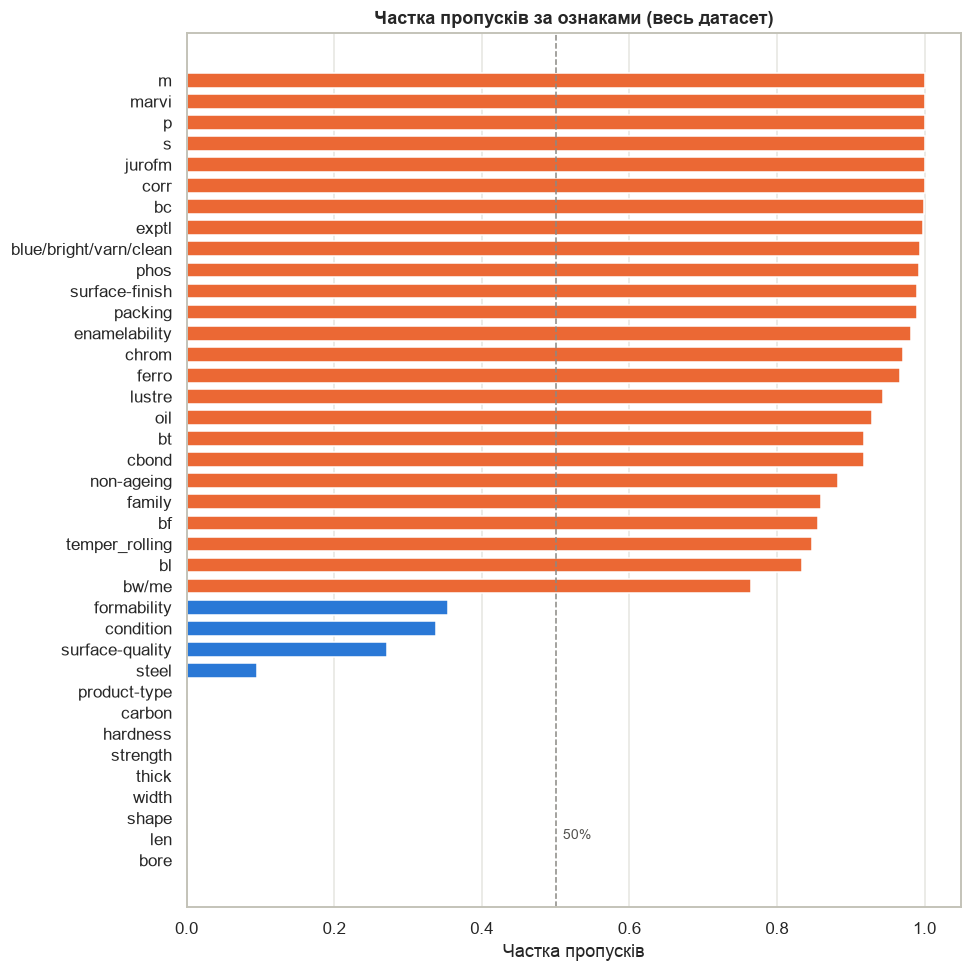

Ознак без пропусків: 9, з пропусками > 50%: 25, повністю порожніх: 6


In [3]:
missing_share = X_full.isna().mean().sort_values()
fig, ax = plt.subplots(figsize=(9, 9))
bar_colors = [COLORS["orange"] if share > 0.5 else COLORS["blue"] for share in missing_share]
ax.barh(missing_share.index, missing_share.values, color=bar_colors, height=0.7)
ax.axvline(0.5, color=COLORS["muted"], linestyle="--", linewidth=1)
ax.set(xlim=(0, 1.05), xlabel="Частка пропусків", ylabel="",
       title="Частка пропусків за ознаками (весь датасет)")
ax.text(0.51, 1, "50%", color="#52514e", fontsize=9)
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()
print(f"Ознак без пропусків: {(missing_share == 0).sum()}, "
      f"з пропусками > 50%: {(missing_share > 0.5).sum()}, повністю порожніх: {(missing_share == 1).sum()}")

**Коментар.** Пропуски в Annealing екстремальні: більшість ознак порожні більш ніж на 80%. Згідно з `anneal.names`, `?` тут здебільшого означає «не застосовно / ознака відсутня» (наприклад, у виробу немає покриття `phos` чи спеціальної обробки `cbond`). Тобто це **структурні пропуски**: ознака з одним спостережуваним значенням `Y` фактично є бінарним прапорцем «є / немає», де «немає» записано як пропуск.

In [4]:
observed_unique = X_full.nunique(dropna=True)
empty_features = missing_share[missing_share == 1].index.tolist()
constant_features = [
    column for column in X_full.columns
    if column not in empty_features and observed_unique[column] == 1 and missing_share[column] == 0
]
X = X_full.drop(columns=empty_features + constant_features)
flag_like_features = [column for column in X.columns if observed_unique[column] == 1]

print("Повністю порожні ознаки (видалено):", sorted(empty_features))
print("Константні ознаки без пропусків (видалено):", constant_features)
print(f"Залишено ознак: {X.shape[1]}")
print(f"Ознаки-прапорці «одне значення або NaN» ({len(flag_like_features)}):", flag_like_features)

Повністю порожні ознаки (видалено): ['corr', 'jurofm', 'm', 'marvi', 'p', 's']
Константні ознаки без пропусків (видалено): ['product-type']
Залишено ознак: 31
Ознаки-прапорці «одне значення або NaN» (13): ['temper_rolling', 'non-ageing', 'surface-finish', 'bc', 'bf', 'bt', 'bl', 'chrom', 'phos', 'cbond', 'exptl', 'ferro', 'lustre']


**Обґрунтування видалення.**

- Шість ознак (`corr`, `jurofm`, `m`, `marvi`, `p`, `s`) порожні на 100% — вони не містять жодної інформації ні про об'єкт, ні про клас.
- `product-type` приймає одне значення `C` у всіх 898 рядках — константа не може розділити класи.

Ознаки-прапорці з одним спостережуваним значенням і пропусками **не видаляємо**: інформацію несе саме факт пропуску. Зауважимо наслідок для варіанту A: імпутація модою заповнить такий стовпець єдиним спостережуваним значенням, він стане константою й уся інформація зникне. Варіант B зберігає її через індикатори пропусків — це головна причина очікувати від B кращої якості.

,кількість,частка
class,,
1,8,0.009
2,99,0.110
3,684,0.762
5,67,0.075
U,40,0.045


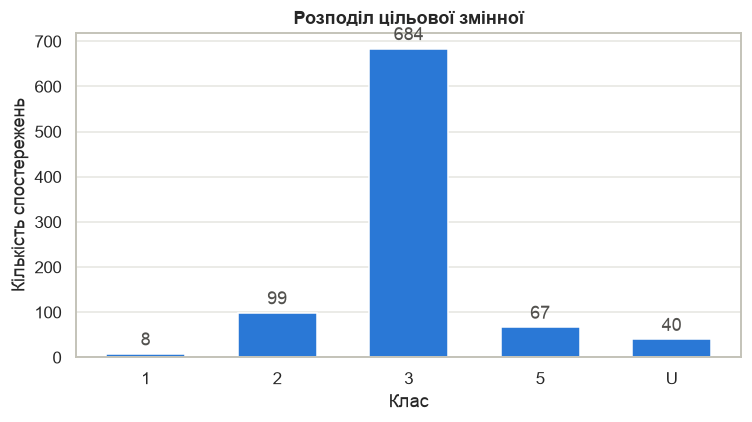

In [5]:
class_counts = y_full.value_counts().sort_index()
class_table = pd.DataFrame({"кількість": class_counts, "частка": (class_counts / len(y_full)).round(3)})
display(class_table)

fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.bar(class_counts.index, class_counts.values, color=COLORS["blue"], width=0.6)
ax.bar_label(bars, padding=3, color="#52514e")
ax.set(title="Розподіл цільової змінної", xlabel="Клас", ylabel="Кількість спостережень")
ax.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()

**Коментар і рішення щодо рідкісного класу.** Розподіл сильно незбалансований: клас `3` займає 76%, а клас `1` має лише **8 спостережень**. Клас `4`, описаний у документації, у даних відсутній. Класи позначено як `1, 2, 3, 5, U`.

Клас `1` **залишаємо** без об'єднання. Він фізично відмінний від інших і, як показує аналіз нижче, має власну сигнатуру (наприклад, тільки в ньому заповнена `exptl`). Об'єднання змінило б саму задачу, а виключення приховало б найскладніший випадок. Наслідки для крос-валідації (див. «Типові помилки», п. 4):

- після поділу 80/20 у train залишиться 6 об'єктів класу `1`, у test — 2;
- 5-блочна стратифікована CV на train дає приблизно 1 такий об'єкт у кожному валідаційному блоці й 4–5 у тренувальному;
- внутрішня 3-блочна CV у вкладеній оцінці працює лише з 4–5 такими об'єктами, тож у її тренувальних блоках може залишитися всього 2. Саме тому внутрішня CV має 3 блоки, а не 5: клас `1` присутній у кожному тренувальному блоці, і XGBoost не падає. Водночас F1 класу `1` на окремому блоці дуже шумний (0 або 1), тому дисперсія macro F1 буде помітною, і порівняння потребує тесту Наде–Бенжіо.

Мінімальні кількості перевіряємо явно на кожному рівні CV нижче.

### Аналіз механізму пропусків

Для п'яти ознак із найбільшою часткою пропусків будуємо таблиці спряженості «пропуск / не пропуск» × клас і перевіряємо незалежність. Частоти дуже малі (є клітинки з 0–2 об'єктами), тому асимптотичний $\chi^2$ ненадійний. Точний тест Фішера в `scipy` реалізований лише для таблиць 2×2, тому для 2×5 використовуємо **перестановочний (умовний) варіант** $\chi^2$ — він не спирається на асимптотику, як і тест Фішера. Ефект оцінюємо V Крамера. Для контрасту додатково перевіряємо три ознаки з помірною часткою пропусків (20–50%), де спостережуваних значень достатньо.

In [6]:
def missingness_test(feature):
    table = pd.crosstab(
        X[feature].isna().map({True: "пропуск", False: "не пропуск"}).rename(feature),
        y_full,
    )
    asymptotic = stats.chi2_contingency(table.values, correction=False)
    permutation = stats.chi2_contingency(
        table.values,
        correction=False,
        method=stats.PermutationMethod(n_resamples=9999, rng=np.random.default_rng(SEED)),
    )
    n = table.values.sum()
    cramers_v = np.sqrt(asymptotic.statistic / (n * (min(table.shape) - 1)))
    summary = {
        "ознака": feature,
        "частка пропусків": round(X[feature].isna().mean(), 3),
        "chi2": round(asymptotic.statistic, 2),
        "p (асимпт.)": asymptotic.pvalue,
        "p (перестан.)": permutation.pvalue,
        "мін. очікувана частота": round(asymptotic.expected_freq.min(), 2),
        "V Крамера": round(cramers_v, 3),
    }
    return table, summary


missing_rank = X.isna().mean().sort_values(ascending=False)
top_missing = missing_rank.head(5).index.tolist()
moderate_missing = missing_rank[(missing_rank > 0.2) & (missing_rank < 0.5)].head(3).index.tolist()

test_rows = []
for feature in top_missing + moderate_missing:
    table, summary = missingness_test(feature)
    summary["група"] = "top-5" if feature in top_missing else "помірні"
    test_rows.append(summary)
    display(table)

missingness_results = pd.DataFrame(test_rows).set_index("ознака")
missingness_results["висновок (α=0.05)"] = np.where(
    missingness_results["p (перестан.)"] < 0.05, "пов'язані з класом", "немає підстав відхилити MCAR"
)
display(missingness_results)

class,1,2,3,5,U
bc,,,,,
не пропуск,0,0,1,0,0
пропуск,8,99,683,67,40


class,1,2,3,5,U
exptl,,,,,
не пропуск,2,0,0,0,0
пропуск,6,99,684,67,40


class,1,2,3,5,U
blue/bright/varn/clean,,,,,
не пропуск,1,4,1,0,0
пропуск,7,95,683,67,40


class,1,2,3,5,U
phos,,,,,
не пропуск,0,0,0,7,0
пропуск,8,99,684,60,40


class,1,2,3,5,U
packing,,,,,
не пропуск,0,0,9,0,0
пропуск,8,99,675,67,40


class,1,2,3,5,U
formability,,,,,
не пропуск,0,80,433,67,0
пропуск,8,19,251,0,40


class,1,2,3,5,U
condition,,,,,
не пропуск,0,80,494,21,0
пропуск,8,19,190,46,40


class,1,2,3,5,U
surface-quality,,,,,
не пропуск,0,10,604,0,40
пропуск,8,89,80,67,0


,частка пропусків,chi2,p (асимпт.),p (перестан.),мін. очікувана частота,V Крамера,група,висновок (α=0.05)
ознака,,,,,,,,
bc,0.999,0.31,9.889453e-01,1.0000,0.01,0.019,top-5,немає підстав відхилити MCAR
exptl,0.998,223.00,4.246571e-47,0.0002,0.02,0.498,top-5,пов'язані з класом
blue/bright/varn/clean,0.993,37.37,1.514610e-07,0.0011,0.05,0.204,top-5,пов'язані з класом
phos,0.992,87.50,4.464519e-18,0.0001,0.06,0.312,top-5,пов'язані з класом
packing,0.990,2.84,5.842109e-01,0.4456,0.08,0.056,top-5,немає підстав відхилити MCAR
formability,0.354,136.16,1.870974e-28,0.0001,2.83,0.389,помірні,пов'язані з класом
condition,0.337,151.05,1.214184e-31,0.0001,2.70,0.410,помірні,пов'язані з класом
surface-quality,0.272,495.58,6.052245e-106,0.0001,2.17,0.743,помірні,пов'язані з класом


**Висновок щодо механізму пропусків.** Для трьох із п'яти найбільш порожніх ознак (`exptl`, `blue/bright/varn/clean`, `phos`) перестановочний тест відхиляє незалежність пропуску від класу ($p \le 0.0011$) з помірним або сильним ефектом (V Крамера 0.20–0.50). Таблиці показують, що це «підписи» класів, а не випадковість: `exptl` заповнена лише у двох об'єктів, і обидва належать класу `1`; `phos` заповнена тільки в класі `5`.

Для `bc` (одне спостережуване значення) і `packing` (9 значень, усі в класі `3`) тест незначущий. Але це питання потужності: при 1–9 непропущених значеннях жоден тест не здатен виявити зв'язок, тож «немає підстав відхилити MCAR» тут **не означає**, що пропуски справді MCAR.

Найсильніший зв'язок мають ознаки з помірною часткою пропусків, де статистика надійна. Для `surface-quality` V Крамера = 0.74: у класі `3` ознака заповнена в 88% об'єктів, а в класах `1` і `5` порожня завжди.

Отже, пропуски в Annealing **не є MCAR**: вони структурні й пов'язані з класом. Розрізнити MAR (залежність від типу продукції) і MNAR за самими даними неможливо. Звідси гіпотеза для п. 3.3: індикатори пропусків (варіант B) повинні помітно покращити якість.

In [7]:
label_encoder = LabelEncoder()
y = label_encoder.fit_transform(y_full)
class_names = label_encoder.classes_.astype(str)
display(pd.DataFrame({"клас": class_names, "код": range(len(class_names))}).set_index("клас").T)

клас,1,2,3,5,U
код,0,1,2,3,4


## 3.2 Поділ даних і пайплайн обробки

Стратифікований поділ 80/20. Тестова вибірка використовується **один раз** — у п. 3.6 (і далі лише для інтерпретації вже зафіксованих фінальних моделей).

In [8]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=SEED
)
split_table = pd.DataFrame({
    "train": np.bincount(y_train, minlength=len(class_names)),
    "test": np.bincount(y_test, minlength=len(class_names)),
}, index=class_names)
split_table.loc["усього"] = split_table.sum()
display(split_table.T)

,1,2,3,5,U,усього
train,6,79,547,54,32,718
test,2,20,137,13,8,180


**Варіант A** — медіана для числових ознак, мода для категоріальних, one-hot кодування.
**Варіант B** — те саме плюс бінарні індикатори `MissingIndicator(features='missing-only')` для кожної ознаки, що мала пропуски в тренувальних даних.

Уся обробка живе **всередині `Pipeline`**: імпутер, кодувальник та індикатори навчаються лише на тренувальній частині кожного блоку CV. Невідомі категорії з валідації кодуються нулями (`handle_unknown='ignore'`). Для `MissingIndicator` встановлено `error_on_new=False`, щоб пропуск у валідаційному блоці в ознаці, яка в тренувальному блоці була повною, не зупиняв CV. Така ознака просто не отримує індикатора, як і передбачає `features='missing-only'`.

In [9]:
def build_preprocessor(with_indicators: bool) -> ColumnTransformer:
    transformers = [
        ("num", SimpleImputer(strategy="median"),
         make_column_selector(dtype_include="number")),
        ("cat", Pipeline([
            ("impute", SimpleImputer(strategy="most_frequent")),
            ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
        ]), make_column_selector(dtype_exclude="number")),
    ]
    if with_indicators:
        transformers.append(
            ("miss", MissingIndicator(features="missing-only", error_on_new=False),
             make_column_selector()))
    return ColumnTransformer(transformers)


def make_model(name, params=None):
    params = params or {}
    if name == "DT":
        return DecisionTreeClassifier(random_state=SEED, **params)
    if name == "RF":
        return RandomForestClassifier(random_state=SEED, n_jobs=-1, **params)
    return XGBClassifier(random_state=SEED, n_jobs=-1, eval_metric="mlogloss", **params)


def build_pipeline(name, with_indicators=True, params=None):
    return Pipeline([("prep", build_preprocessor(with_indicators)),
                     ("clf", make_model(name, params))])


for with_indicators in (False, True):
    shape = build_preprocessor(with_indicators).fit_transform(X_train).shape
    print(f"Варіант {'B' if with_indicators else 'A'}: {shape[1]} ознак після обробки train")

Варіант A: 54 ознак після обробки train
Варіант B: 77 ознак після обробки train


## 3.3 Базові моделі

Три моделі з типовими гіперпараметрами для кожного варіанту обробки. Оцінка — повторна стратифікована CV (5 блоків × 3 повторення) на train за accuracy, **macro F1** (основна) і balanced accuracy. Усі шість конфігурацій використовують **той самий об'єкт `cv`**, тобто однакові блоки, що потрібно для парного тесту в п. 3.5.

In [10]:
scoring = {"acc": "accuracy", "f1m": "f1_macro", "bacc": "balanced_accuracy"}
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=SEED)

fold_minima = np.array([
    [np.bincount(y_train[tr], minlength=len(class_names)).min(),
     np.bincount(y_train[va], minlength=len(class_names)).min()]
    for tr, va in cv.split(X_train, y_train)
])
first_train, first_val = next(cv.split(X_train, y_train))
N_TRAIN_FOLD, N_TEST_FOLD = len(first_train), len(first_val)
print(f"Мінімум об'єктів класу в тренувальних блоках: {fold_minima[:, 0].min()}, "
      f"у валідаційних: {fold_minima[:, 1].min()}")
print(f"Розмір блоку: train={N_TRAIN_FOLD}, validation={N_TEST_FOLD}")

cv_results = {}
started = time.perf_counter()
for variant, with_indicators in (("A", False), ("B", True)):
    for name in MODEL_NAMES:
        cv_results[(variant, name)] = cross_validate(
            build_pipeline(name, with_indicators), X_train, y_train, cv=cv, scoring=scoring
        )
print(f"Час: {time.perf_counter() - started:.1f} с")


def cv_table(variant):
    rows = {}
    for name in MODEL_NAMES:
        result = cv_results[(variant, name)]
        rows[MODEL_TITLES[name]] = {
            title: f"{result[f'test_{key}'].mean():.4f} ± {result[f'test_{key}'].std(ddof=1):.4f}"
            for key, title in (("acc", "accuracy"), ("f1m", "macro F1"), ("bacc", "balanced accuracy"))
        }
    return pd.DataFrame(rows).T


display(Markdown("**Таблиця 1.** Крос-валідація (5×3), варіант A, типові параметри"))
display(cv_table("A"))
display(Markdown("**Таблиця 2.** Крос-валідація (5×3), варіант B, типові параметри"))
display(cv_table("B"))

Мінімум об'єктів класу в тренувальних блоках: 4, у валідаційних: 1
Розмір блоку: train=574, validation=144


Час: 10.8 с


**Таблиця 1.** Крос-валідація (5×3), варіант A, типові параметри

,accuracy,macro F1,balanced accuracy
Decision Tree,0.9526 ± 0.0121,0.9221 ± 0.0541,0.9228 ± 0.0638
Random Forest,0.9471 ± 0.0134,0.9334 ± 0.0159,0.9331 ± 0.0280
XGBoost,0.9508 ± 0.0137,0.9168 ± 0.0548,0.9109 ± 0.0549


**Таблиця 2.** Крос-валідація (5×3), варіант B, типові параметри

,accuracy,macro F1,balanced accuracy
Decision Tree,0.9912 ± 0.0061,0.9872 ± 0.0103,0.9892 ± 0.0138
Random Forest,0.9940 ± 0.0064,0.9884 ± 0.0140,0.9864 ± 0.0165
XGBoost,0.9907 ± 0.0073,0.9713 ± 0.0518,0.9684 ± 0.0538


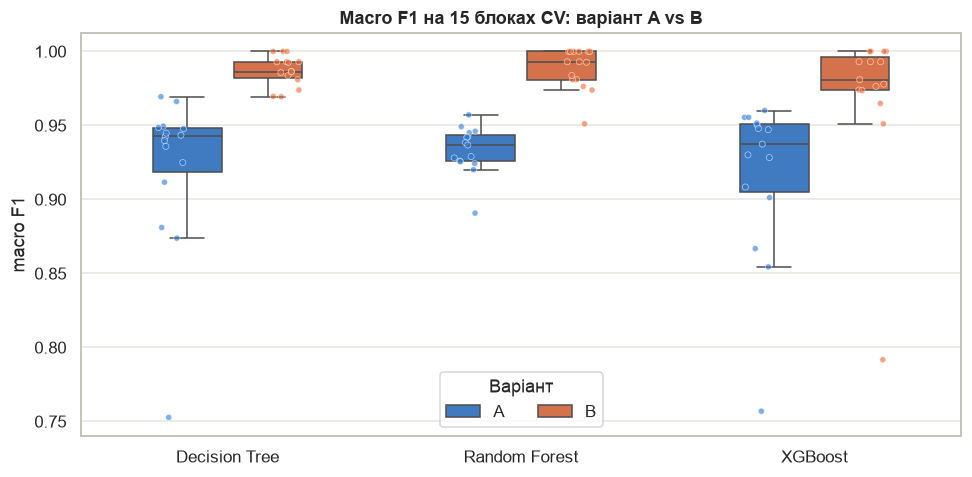

In [11]:
fold_scores = pd.DataFrame([
    {"модель": MODEL_TITLES[name], "варіант": variant, "macro F1": score}
    for (variant, name), result in cv_results.items()
    for score in result["test_f1m"]
])
fig, ax = plt.subplots(figsize=(9, 4.5))
sns.boxplot(data=fold_scores, x="модель", y="macro F1", hue="варіант",
            palette={"A": COLORS["blue"], "B": COLORS["orange"]}, width=0.55,
            gap=0.15, linewidth=1, fliersize=0, ax=ax)
sns.stripplot(data=fold_scores, x="модель", y="macro F1", hue="варіант", dodge=True,
              palette={"A": COLORS["blue"], "B": COLORS["orange"]}, size=4, alpha=0.6,
              edgecolor="white", linewidth=0.5, legend=False, ax=ax)
ax.set(title="Macro F1 на 15 блоках CV: варіант A vs B", xlabel="")
ax.legend(title="Варіант", loc="lower center", ncol=2)
plt.tight_layout()
plt.show()

**Коментар.** Індикатори пропусків дають найбільший ефект у всій роботі. Macro F1 зростає на 0.055–0.065 для всіх трьох моделей (DT 0.922 → 0.987, RF 0.933 → 0.988, XGBoost 0.917 → 0.971), accuracy — з ≈ 0.95 до ≈ 0.99. Це пряме підтвердження аналізу пропусків. У варіанті A 13 ознак-прапорців після імпутації модою стають константами, а в `surface-quality`, `formability`, `condition` пропуск зливається з найчастішим значенням. Інформація «ознака не застосовна» зникає, хоча саме вона найсильніше пов'язана з класом.

Варіант B також різко зменшує розкид: std macro F1 у DT падає з 0.054 до 0.010. На boxplot видно, що у варіанті A окремі блоки провалюються до macro F1 ≈ 0.75. Це блоки, де модель повністю пропускає рідкісний клас `1`: при 1–2 його об'єктах у блоці одна помилка знижує macro F1 на 0.1–0.2. Велике std XGBoost у B (0.052) дає один такий блок (≈ 0.79).

Ефект стелі видно вже тут: accuracy усіх моделей у B ≈ 0.99, а середні macro F1 DT і RF різняться лише на 0.001. Тому висновки про переваги робимо за статистичним тестом у п. 3.5, а не за середніми.

## 3.4 Підбір гіперпараметрів за допомогою Optuna

Оптимізація виконується для варіанту B. У цільову функцію передається **весь пайплайн** (обробка + модель) і сирий `X_tr`, тому імпутер та індикатори навчаються тільки на тренувальних блоках внутрішньої 3-блочної CV, без витоку даних. Семплер TPE ініціалізовано `SEED`, 30 спроб на кожен запуск.

In [12]:
N_TRIALS = 30


def suggest_params(trial, name):
    if name == "DT":
        return {
            "max_depth": trial.suggest_int("max_depth", 2, 20),
            "min_samples_split": trial.suggest_int("min_samples_split", 2, 20),
            "min_samples_leaf": trial.suggest_int("min_samples_leaf", 1, 10),
            "class_weight": trial.suggest_categorical("class_weight", [None, "balanced"]),
        }
    if name == "RF":
        return {
            "n_estimators": trial.suggest_int("n_estimators", 100, 500, step=50),
            "max_depth": trial.suggest_int("max_depth", 3, 30),
            "min_samples_leaf": trial.suggest_int("min_samples_leaf", 1, 10),
            "max_features": trial.suggest_categorical("max_features", ["sqrt", "log2", 0.5]),
            "class_weight": trial.suggest_categorical(
                "class_weight", [None, "balanced", "balanced_subsample"]),
        }
    return {
        "n_estimators": trial.suggest_int("n_estimators", 50, 400),
        "max_depth": trial.suggest_int("max_depth", 2, 10),
        "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.3, log=True),
        "subsample": trial.suggest_float("subsample", 0.6, 1.0),
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.6, 1.0),
        "min_child_weight": trial.suggest_float("min_child_weight", 1, 10, log=True),
    }


def tune(name, X_tr, y_tr, n_trials=N_TRIALS):
    inner = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)

    def objective(trial):
        pipe = build_pipeline(name, True, suggest_params(trial, name))
        return cross_val_score(pipe, X_tr, y_tr, cv=inner, scoring="f1_macro").mean()

    study = optuna.create_study(
        direction="maximize",
        sampler=optuna.samplers.TPESampler(seed=SEED))
    study.optimize(objective, n_trials=n_trials)
    return study

### Вкладена крос-валідація

Зовнішній цикл — 5-блочна стратифікована CV на train. На кожному зовнішньому блоці `tune()` запускається **лише на його тренувальній частині**, модель з найкращими параметрами навчається на ній і оцінюється на зовнішній валідаційній частині, яку Optuna не бачила. Отже, оцінюється вся процедура «підбір + навчання», а не одна конкретна модель.

In [13]:
outer = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
inner_check = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)

inner_minimum = min(
    np.bincount(y_train[tr_idx][inner_tr], minlength=len(class_names)).min()
    for tr_idx, _ in outer.split(X_train, y_train)
    for inner_tr, _ in inner_check.split(X_train.iloc[tr_idx], y_train[tr_idx])
)
outer_minimum = min(
    np.bincount(y_train[tr_idx], minlength=len(class_names)).min()
    for tr_idx, _ in outer.split(X_train, y_train)
)
print(f"Мінімум об'єктів класу: зовнішні train-блоки = {outer_minimum}, внутрішні train-блоки = {inner_minimum}")

nested_scores = {name: [] for name in MODEL_NAMES}
nested_params = {name: [] for name in MODEL_NAMES}
nested_times = {}
for name in MODEL_NAMES:
    started = time.perf_counter()
    for tr_idx, va_idx in outer.split(X_train, y_train):
        X_tr, y_tr = X_train.iloc[tr_idx], y_train[tr_idx]
        X_va, y_va = X_train.iloc[va_idx], y_train[va_idx]
        study = tune(name, X_tr, y_tr)
        model = build_pipeline(name, True, study.best_params).fit(X_tr, y_tr)
        nested_scores[name].append(f1_score(y_va, model.predict(X_va), average="macro"))
        nested_params[name].append(study.best_params)
    nested_times[name] = time.perf_counter() - started
    print(f"{MODEL_TITLES[name]}: macro F1 по зовнішніх блоках = "
          f"{np.round(nested_scores[name], 4).tolist()} ({nested_times[name]:.0f} с)")

Мінімум об'єктів класу: зовнішні train-блоки = 4, внутрішні train-блоки = 2


Decision Tree: macro F1 по зовнішніх блоках = [0.9837, 0.9728, 0.9735, 0.961, 1.0] (7 с)


Random Forest: macro F1 по зовнішніх блоках = [1.0, 0.9922, 0.9837, 0.9739, 0.9809] (122 с)


XGBoost: macro F1 по зовнішніх блоках = [1.0, 0.9857, 1.0, 0.9673, 0.9809] (241 с)


### Фінальні моделі

Запускаємо `tune()` на **всій** тренувальній вибірці, навчаємо кожну модель з найкращими параметрами та зберігаємо в `models/`. Значення `study.best_value` цього запуску — це «звичайна» оцінка, яку порівнюємо з вкладеною CV.

In [14]:
final_studies = {}
final_models = {}
for name in MODEL_NAMES:
    final_studies[name] = tune(name, X_train, y_train)
    final_models[name] = build_pipeline(name, True, final_studies[name].best_params).fit(X_train, y_train)
    joblib.dump(final_models[name], MODELS_DIR / f"{name.lower()}_variant_b.joblib")

nested_table = pd.DataFrame({
    MODEL_TITLES[name]: {
        "вкладена CV macro F1 (mean ± std)":
            f"{np.mean(nested_scores[name]):.4f} ± {np.std(nested_scores[name], ddof=1):.4f}",
        "best_value (Optuna на всьому train)": f"{final_studies[name].best_value:.4f}",
        "best_value − nested": f"{final_studies[name].best_value - np.mean(nested_scores[name]):+.4f}",
        "типові параметри, CV 5×3 (варіант B)": f"{cv_results[('B', name)]['test_f1m'].mean():.4f}",
    }
    for name in MODEL_NAMES
}).T
display(Markdown("**Таблиця 3.** Вкладена крос-валідація (варіант B, після оптимізації) і `best_value`"))
display(nested_table)

params_table = pd.DataFrame([
    {"модель": MODEL_TITLES[name], "гіперпараметр": key,
     "значення": str(round(value, 4) if isinstance(value, float) else value)}
    for name in MODEL_NAMES for key, value in final_studies[name].best_params.items()
]).set_index(["модель", "гіперпараметр"])
display(Markdown("**Таблиця 4.** Найкращі гіперпараметри, знайдені Optuna на всьому train"))
display(params_table)
print("Збережені моделі:", sorted(path.name for path in MODELS_DIR.glob("*.joblib")))

**Таблиця 3.** Вкладена крос-валідація (варіант B, після оптимізації) і `best_value`

,вкладена CV macro F1 (mean ± std),best_value (Optuna на всьому train),best_value − nested,"типові параметри, CV 5×3 (варіант B)"
Decision Tree,0.9782 ± 0.0146,0.8924,-0.0858,0.9872
Random Forest,0.9861 ± 0.0101,0.9231,-0.0631,0.9884
XGBoost,0.9868 ± 0.0138,0.9171,-0.0697,0.9713


**Таблиця 4.** Найкращі гіперпараметри, знайдені Optuna на всьому train

значення
модель        гіперпараметр             
Decision Tree max_depth               14
              min_samples_split        2
              min_samples_leaf         1
              class_weight          None
Random Forest n_estimators           150
              max_depth               27
              min_samples_leaf         1
              max_features          sqrt
              class_weight          None
XGBoost       n_estimators           371
              max_depth               10
              learning_rate       0.0433
              subsample           0.8142
              colsample_bytree    0.6292
              min_child_weight    1.1973

Збережені моделі: ['dt_variant_b.joblib', 'rf_variant_b.joblib', 'xgb_variant_b.joblib']


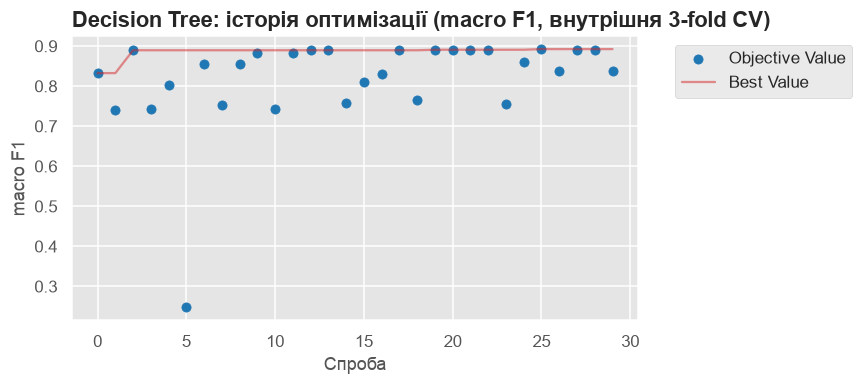

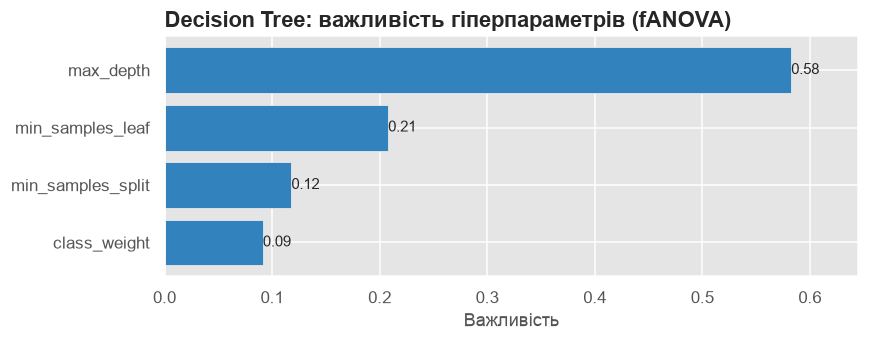

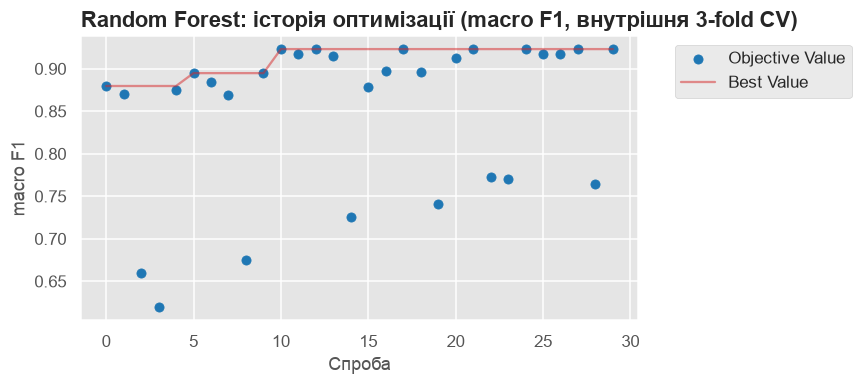

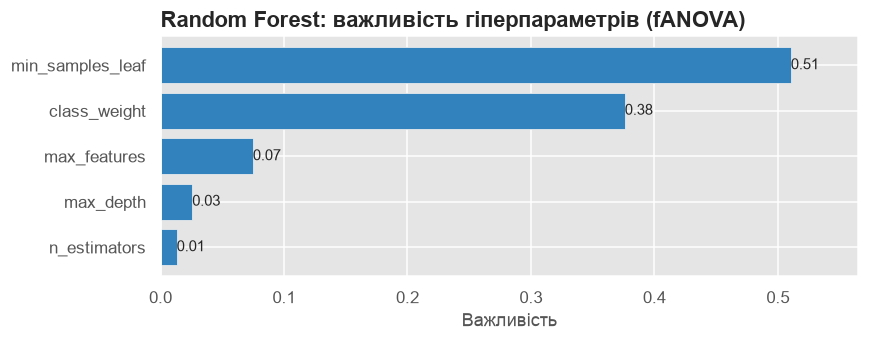

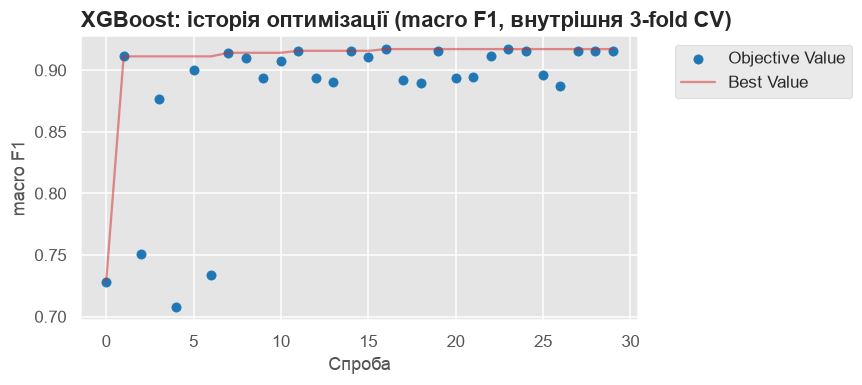

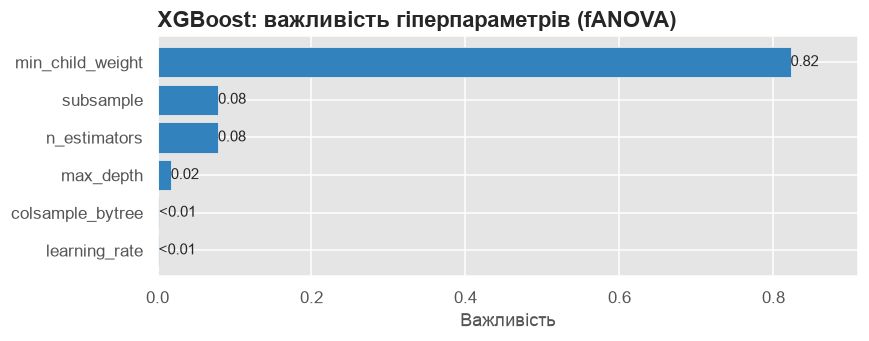

,найкраща спроба №,best_value,медіана спроб,спроб із ≥ 99% best_value
Decision Tree,25,0.8924,0.8554,11
Random Forest,10,0.9231,0.8948,11
XGBoost,16,0.9171,0.9039,14


In [15]:
from optuna.importance import FanovaImportanceEvaluator
from optuna.visualization.matplotlib import plot_optimization_history, plot_param_importances

def retitle(ax, title):
    for location in ("left", "center", "right"):
        ax.set_title("", loc=location)
    ax.set_title(title, loc="left")


for name in MODEL_NAMES:
    study = final_studies[name]
    with plt.rc_context():
        ax = plot_optimization_history(study)
        ax.figure.set_size_inches(8, 3.6)
        retitle(ax, f"{MODEL_TITLES[name]}: історія оптимізації (macro F1, внутрішня 3-fold CV)")
        ax.set(xlabel="Спроба", ylabel="macro F1")
        plt.tight_layout()
        plt.show()

        ax = plot_param_importances(study, evaluator=FanovaImportanceEvaluator(seed=SEED))
        ax.figure.set_size_inches(8, 3.2)
        retitle(ax, f"{MODEL_TITLES[name]}: важливість гіперпараметрів (fANOVA)")
        ax.set(xlabel="Важливість", ylabel="")
        legend = ax.get_legend()
        if legend is not None:
            legend.remove()
        plt.tight_layout()
        plt.show()

convergence = pd.DataFrame.from_dict(orient="index", data={
    MODEL_TITLES[name]: {
        "найкраща спроба №": final_studies[name].best_trial.number,
        "best_value": round(final_studies[name].best_value, 4),
        "медіана спроб": round(np.median([t.value for t in final_studies[name].trials]), 4),
        "спроб із ≥ 99% best_value": sum(t.value >= 0.99 * final_studies[name].best_value
                                         for t in final_studies[name].trials),
    }
    for name in MODEL_NAMES
})
display(convergence)

### Чому `best_value` нижчий за оцінку вкладеної CV

Теорія очікує зворотного (`best_value` — максимум із 30 зашумлених оцінок), тому перевіряємо, що саме занижує `best_value`. Оцінюємо **ті самі** фінальні параметри за двома схемами розбиття train: 3-блочною, як у `tune()`, і 5-блочною, як у зовнішньому циклі. Окремо рахуємо F1 рідкісного класу `1` і macro F1 без нього.

In [16]:
class_one = int(np.flatnonzero(class_names == "1")[0])
other_classes = [label for label in range(len(class_names)) if label != class_one]
diagnostic_scoring = {
    "f1m": "f1_macro",
    "f1_one": make_scorer(f1_score, labels=[class_one], average="macro", zero_division=0),
    "f1m_without_one": make_scorer(f1_score, labels=other_classes, average="macro", zero_division=0),
}
inner_diagnostic = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)
diagnostic_rows = []
for name in MODEL_NAMES:
    for scheme, splitter in (("3-fold, як у tune()", inner_diagnostic), ("5-fold, як зовнішній цикл", outer)):
        result = cross_validate(build_pipeline(name, True, final_studies[name].best_params),
                                X_train, y_train, cv=splitter, scoring=diagnostic_scoring)
        diagnostic_rows.append({
            "модель": MODEL_TITLES[name],
            "схема": scheme,
            "macro F1 по блоках": np.round(result["test_f1m"], 3).tolist(),
            "середнє macro F1": round(result["test_f1m"].mean(), 4),
            "F1 класу 1 по блоках": np.round(result["test_f1_one"], 2).tolist(),
            "macro F1 без класу 1": round(result["test_f1m_without_one"].mean(), 4),
        })
display(pd.DataFrame(diagnostic_rows).set_index(["модель", "схема"]))

class_one_rows = X_train.index[y_train == class_one]
print("Об'єкти класу 1 у валідаційних блоках 3-fold:",
      [sorted(X_train.index[va][y_train[va] == class_one].tolist()) for _, va in inner_diagnostic.split(X_train, y_train)])
display(X.loc[class_one_rows, ["steel", "carbon", "strength", "exptl", "shape", "thick", "width"]]
        .astype(object).where(lambda frame: frame.notna(), "NaN"))

macro F1 по блоках  \
модель        схема                                                          
Decision Tree 3-fold, як у tune()                     [0.972, 0.96, 0.745]   
              5-fold, як зовнішній цикл  [0.984, 0.986, 0.981, 0.986, 1.0]   
Random Forest 3-fold, як у tune()                      [0.996, 1.0, 0.774]   
              5-fold, як зовнішній цикл    [1.0, 0.993, 1.0, 0.974, 0.981]   
XGBoost       3-fold, як у tune()                    [0.996, 0.991, 0.764]   
              5-fold, як зовнішній цикл  [1.0, 0.993, 0.932, 0.974, 0.981]   

                                         середнє macro F1  \
модель        схема                                         
Decision Tree 3-fold, як у tune()                  0.8924   
              5-fold, як зовнішній цикл            0.9873   
Random Forest 3-fold, як у tune()                  0.9231   
              5-fold, як зовнішній цикл            0.9895   
XGBoost       3-fold, як у tune()                  0.9171   
              5-fold, як зовнішній цикл            0.9760   

                                               F1 класу 1 по блоках  \
модель        схема                                                   
Decision Tree 3-fold, як у tune()                   [1.0, 1.0, 0.0]   
              5-fold, як зовнішній цикл   [1.0, 1.0, 1.0, 1.0, 1.0]   
Random Forest 3-fold, як у tune()                   [1.0, 1.0, 0.0]   
              5-fold, як зовнішній цикл   [1.0, 1.0, 1.0, 1.0, 1.0]   
XGBoost       3-fold, як у tune()                   [1.0, 1.0, 0.0]   
              5-fold, як зовнішній цикл  [1.0, 1.0, 0.67, 1.0, 1.0]   

                                         macro F1 без класу 1  
модель        схема                                            
Decision Tree 3-fold, як у tune()                      0.9489  
              5-fold, як зовнішній цикл                0.9842  
Random Forest 3-fold, як у tune()                      0.9872  
              5-fold, як зовнішній цикл                0.9869  
XGBoost       3-fold, як у tune()                      0.9797  
              5-fold, як зовнішній цикл                0.9866

Об'єкти класу 1 у валідаційних блоках 3-fold: [[278, 341], [119, 288], [188, 364]]


,steel,carbon,strength,exptl,shape,thick,width
278,S,0,400,NaN,COIL,0.8,609.9
341,S,0,400,NaN,COIL,0.8,75.0
119,S,0,400,NaN,COIL,0.8,75.0
188,R,0,300,Y,COIL,0.8,915.1
364,R,0,300,Y,COIL,0.8,915.0
288,S,0,400,NaN,COIL,1.0,75.0


**Коментар до оптимізації.**

*Чи збіглася оптимізація.* DT виходить на плато ≈ 0.89 уже на 3-й спробі. Подальші спроби лише незначно уточнюють результат (найкраща — № 25, +0.002), і 11 із 30 лежать у межах 1% від `best_value`: простір пошуку DT малий. RF досягає найкращого значення на 10-й спробі, XGBoost — на 16-й. Відповідно 11 і 14 спроб потрапляють у межі 1% від найкращої, а останні спроби приросту не дають, тож 30 спроб для цієї задачі достатньо.

*Найважливіші гіперпараметри (fANOVA).* Для DT — `max_depth` (0.58): мілке дерево не доходить до розщеплень, що відокремлюють рідкісні класи. Для RF — `min_samples_leaf` (0.51) і `class_weight` (0.38). Для XGBoost — `min_child_weight` (0.82). Усі вони керують тим, чи може модель виділити окремий лист для 4–5 об'єктів класу `1`. Learning rate, `colsample_bytree` і кількість дерев майже не впливають. Отже, якість тут визначає передусім здатність моделі «помітити» рідкісний клас.

*Табл. 3: `best_value` нижчий за вкладену CV (0.89–0.92 проти 0.978–0.987).* Теорія очікує протилежного, і діагностика вище пояснює причину. У 3-блочному розбитті train обидва об'єкти класу `1` з `exptl = Y` (#188 і #364, сталь `R`, `strength = 300`) потрапляють в **один** валідаційний блок. Тоді в тренувальній частині немає жодного прикладу цього підтипу, F1 класу `1` = 0, і macro F1 блоку падає до 0.75–0.77 для всіх трьох моделей. Без класу `1` схеми майже збігаються: RF 0.987 / 0.987, XGBoost 0.980 / 0.987. У DT різниця лишається й без класу `1` (0.949 / 0.984): одне глибоке дерево, навчене на 479 об'єктах замість 574, гірше відтворює й інші рідкісні підтипи.

Оптимістичне зміщення при цьому нікуди не зникає. У межах одного фіксованого розбиття `best_value` перевищує медіану 30 спроб на 0.013–0.037 — саме на стільки ми переоцінили б якість, обравши максимум. Але на датасеті, де клас має 6 об'єктів, випадкове розміщення цих об'єктів у блоках змінює оцінку в кілька разів сильніше. Тому `best_value` не можна подавати як оцінку якості в жодному напрямі; неупереджену оцінку дає лише вкладена CV.

## 3.5 Статистичне порівняння (скоригований t-тест Наде–Бенжіо)

Різниці $d_j$ беремо з п. 3.3: обидві моделі оцінювалися на тих самих 15 блоках. Статистика

$$t = \frac{\bar d}{\sqrt{\hat\sigma_d^2\left(\frac{1}{kr} + \frac{n_\text{test}}{n_\text{train}}\right)}},\qquad \text{df} = kr - 1,$$

де $k = 5$, $r = 3$, а $n_\text{test}/n_\text{train}$ — відношення розмірів валідаційної та тренувальної частин блоку. Якщо всі $d_j = 0$, різниці немає: $t = 0$, $p = 1$.

In [17]:
def nadeau_bengio_test(scores_a, scores_b, n_train=N_TRAIN_FOLD, n_test=N_TEST_FOLD):
    differences = np.asarray(scores_a) - np.asarray(scores_b)
    kr = len(differences)
    mean_difference = differences.mean()
    variance = differences.var(ddof=1)
    if variance == 0:
        t_statistic = 0.0 if mean_difference == 0 else np.sign(mean_difference) * np.inf
    else:
        t_statistic = mean_difference / np.sqrt(variance * (1 / kr + n_test / n_train))
    p_value = 2 * stats.t.sf(abs(t_statistic), df=kr - 1)
    return mean_difference, t_statistic, p_value


comparisons = [
    (f"{MODEL_TITLES[name]}: B − A", cv_results[("B", name)]["test_f1m"], cv_results[("A", name)]["test_f1m"])
    for name in MODEL_NAMES
]
ranking_b = sorted(MODEL_NAMES, key=lambda name: cv_results[("B", name)]["test_f1m"].mean(), reverse=True)
best_b, second_b = ranking_b[:2]
comparisons.append((
    f"Варіант B: {MODEL_TITLES[best_b]} − {MODEL_TITLES[second_b]}",
    cv_results[("B", best_b)]["test_f1m"],
    cv_results[("B", second_b)]["test_f1m"],
))

test_rows = []
for title, scores_a, scores_b in comparisons:
    mean_difference, t_statistic, p_value = nadeau_bengio_test(scores_a, scores_b)
    naive_p = stats.ttest_rel(scores_a, scores_b).pvalue if np.any(scores_a != scores_b) else 1.0
    test_rows.append({
        "порівняння": title,
        "d̄ (macro F1)": round(mean_difference, 4),
        "t": round(t_statistic, 3),
        "p (Наде–Бенжіо)": round(p_value, 4),
        "p (звичайний парний t)": round(naive_p, 4),
        "висновок (α = 0.05)": "різниця значуща" if p_value < 0.05 else "різниця незначуща",
    })

display(Markdown(f"**Таблиця 5.** Скоригований t-тест Наде–Бенжіо, $n_{{test}}/n_{{train}} = {N_TEST_FOLD}/{N_TRAIN_FOLD}$, df = 14"))
statistical_table = pd.DataFrame(test_rows).set_index("порівняння")
display(statistical_table)

**Таблиця 5.** Скоригований t-тест Наде–Бенжіо, $n_{test}/n_{train} = 144/574$, df = 14

,d̄ (macro F1),t,p (Наде–Бенжіо),p (звичайний парний t),висновок (α = 0.05)
порівняння,,,,,
Decision Tree: B − A,0.0650,2.225,0.0430,0.0003,різниця значуща
Random Forest: B − A,0.0550,4.991,0.0002,0.0000,різниця значуща
XGBoost: B − A,0.0545,2.454,0.0278,0.0001,різниця значуща
Варіант B: Random Forest − Decision Tree,0.0012,0.137,0.8927,0.7688,різниця незначуща


**Коментар.** Перевага варіанту B значуща для всіх трьох моделей навіть після поправки Наде–Бенжіо: $p = 0.043$ (DT), $0.0002$ (RF), $0.028$ (XGBoost). Для DT і XGBoost запас невеликий. Їхні різниці по блоках дуже нерівномірні (у варіанті A окремі блоки провалюються до ≈ 0.75), тож велика дисперсія $d_j$ зменшує $t$. Для RF різниці стабільні, і $t = 4.99$.

Звичайний парний t-тест дав би $p \le 0.0003$ для всіх трьох порівнянь, тобто в 100–200 разів «упевненіший» висновок. Це наслідок ігнорування кореляції між блоками, тренувальні частини яких перетинаються на ~75%.

Дві найкращі моделі у варіанті B — Random Forest (0.9884) і Decision Tree (0.9872). Різниця становить 0.0012, $p = 0.89$, тобто **статистично вони не розрізняються**. Це прояв ефекту стелі: на цьому датасеті спосіб обробки пропусків важить значно більше, ніж вибір між деревом і ансамблем.

## 3.6 Фінальна оцінка на тестовій вибірці

Найкращу модель обираємо **за вкладеною CV** (п. 3.4), а не за тестом, щоб тест залишався незалежною оцінкою.

In [18]:
test_rows = {}
test_predictions = {}
for name in MODEL_NAMES:
    prediction = final_models[name].predict(X_test)
    test_predictions[name] = prediction
    test_rows[MODEL_TITLES[name]] = {
        "accuracy": accuracy_score(y_test, prediction),
        "macro F1": f1_score(y_test, prediction, average="macro"),
        "balanced accuracy": balanced_accuracy_score(y_test, prediction),
        "помилок (з 180)": int((prediction != y_test).sum()),
    }
display(Markdown("**Таблиця 6.** Якість фінальних моделей (варіант B, після Optuna) на тестовій вибірці"))
test_table = pd.DataFrame.from_dict(test_rows, orient="index").round(4)
display(test_table)

best_name = max(MODEL_NAMES, key=lambda name: np.mean(nested_scores[name]))
print(f"Найкраща модель за вкладеною CV: {MODEL_TITLES[best_name]}")
print("Кількість об'єктів кожного класу в test:",
      ", ".join(f"{c}: {n}" for c, n in zip(class_names, np.bincount(y_test))), "\n")
print(classification_report(y_test, test_predictions[best_name], labels=range(len(class_names)),
                            target_names=class_names, digits=4, zero_division=0))

**Таблиця 6.** Якість фінальних моделей (варіант B, після Optuna) на тестовій вибірці

,accuracy,macro F1,balanced accuracy,помилок (з 180)
Decision Tree,0.9889,0.9270,0.8985,2
Random Forest,0.9944,0.9326,0.9000,1
XGBoost,0.9889,0.9270,0.8985,2


Найкраща модель за вкладеною CV: XGBoost
Кількість об'єктів кожного класу в test: 1: 2, 2: 20, 3: 137, 5: 13, U: 8 

              precision    recall  f1-score   support

           1     1.0000    0.5000    0.6667         2
           2     0.9524    1.0000    0.9756        20
           3     0.9927    0.9927    0.9927       137
           5     1.0000    1.0000    1.0000        13
           U     1.0000    1.0000    1.0000         8

    accuracy                         0.9889       180
   macro avg     0.9890    0.8985    0.9270       180
weighted avg     0.9892    0.9889    0.9880       180



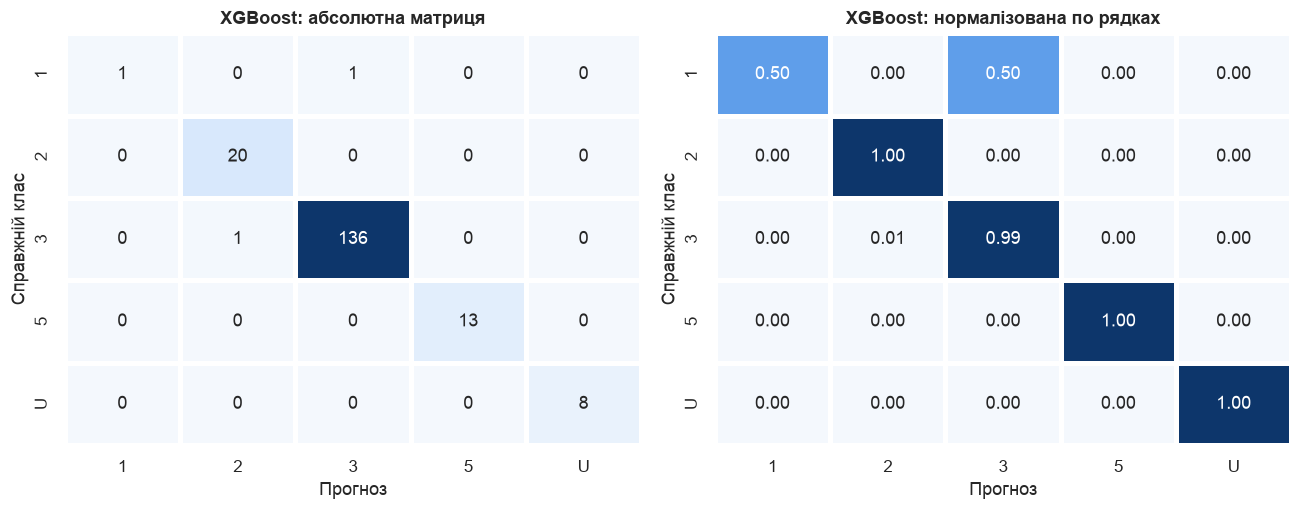

,справжній,прогноз,кількість
0,1,3,1
1,3,2,1


Усі помилки трьох фінальних моделей на тесті:

,модель,справжній,прогноз,кількість
0,Decision Tree,3,2,1
1,Decision Tree,1,3,1
2,Random Forest,1,3,1
3,XGBoost,3,2,1
4,XGBoost,1,3,1


In [19]:
best_prediction = test_predictions[best_name]
absolute_cm = confusion_matrix(y_test, best_prediction, labels=range(len(class_names)))
normalized_cm = confusion_matrix(y_test, best_prediction, labels=range(len(class_names)), normalize="true")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
sns.heatmap(absolute_cm, annot=True, fmt="d", cmap=BLUE_RAMP, cbar=False, linewidths=2, linecolor="white",
            xticklabels=class_names, yticklabels=class_names, ax=axes[0])
axes[0].set(title=f"{MODEL_TITLES[best_name]}: абсолютна матриця", xlabel="Прогноз", ylabel="Справжній клас")
sns.heatmap(normalized_cm, annot=True, fmt=".2f", cmap=BLUE_RAMP, vmin=0, vmax=1, cbar=False, linewidths=2,
            linecolor="white", xticklabels=class_names, yticklabels=class_names, ax=axes[1])
axes[1].set(title=f"{MODEL_TITLES[best_name]}: нормалізована по рядках", xlabel="Прогноз", ylabel="Справжній клас")
plt.tight_layout()
plt.show()

confusions = [
    {"справжній": class_names[i], "прогноз": class_names[j], "кількість": int(absolute_cm[i, j])}
    for i in range(len(class_names)) for j in range(len(class_names)) if i != j and absolute_cm[i, j] > 0
]
display(pd.DataFrame(confusions).sort_values("кількість", ascending=False) if confusions
        else Markdown("Найкраща модель не зробила на тесті жодної помилки."))

all_errors = pd.DataFrame([
    {"модель": MODEL_TITLES[name], "справжній": class_names[t], "прогноз": class_names[p]}
    for name in MODEL_NAMES for t, p in zip(y_test, test_predictions[name]) if t != p
])
if len(all_errors):
    display(Markdown("Усі помилки трьох фінальних моделей на тесті:"))
    display(all_errors.value_counts().rename("кількість").reset_index())

**Коментар.** За accuracy моделі на тесті майже ідеальні (0.989–0.994, тобто 1–2 помилки на 180 об'єктів). Проте macro F1 помітно нижчий за CV-оцінки: 0.927–0.933 проти 0.978–0.987 у вкладеній CV. Причина — один об'єкт. У тесті лише **2** об'єкти класу `1`, і всі три моделі відносять об'єкт #24 до класу `3`. Recall класу `1` дорівнює 0.5, F1 — 0.667, тому цей один об'єкт знижує macro F1 на ≈ 0.067, тоді як accuracy втрачає лише 0.006. Об'єкт #24 справді нетиповий: це єдиний об'єкт класу `1` з `strength = 0` і сталлю `A` (у решти семи — `strength` 300–700 і сталь `R` або `S`). За профілем він не відрізняється від класу `3`. Такий об'єкт може потрапити в тест або в один валідаційний блок CV, тож різниця між тестом і CV — очікуваний наслідок малої кількості прикладів класу, а не перенавчання.

Друга помилка DT і XGBoost — об'єкт #746 (`3` → `2`), детально розібраний у п. 3.8. Random Forest його класифікує правильно, тому на тесті має одну помилку замість двох. За вкладеною CV найкращою обрано XGBoost (0.9868), але RF (0.9861) практично рівний; обидві різниці лежать у межах шуму.

Матриця плутанини найкращої моделі показує дві складні пари: `1` ↔ `3` (рідкісний клас із нетиповим об'єктом) і `3` ↔ `2` (пропущена `surface-quality`, характерна для класу `2`). Класи `5` і `U` розпізнаються бездоганно.

## 3.7 Інтерпретація: важливість ознак

1. **MDI** (`feature_importances_`) обчислюється на оброблених ознаках (після one-hot, з індикаторами), назви — через `get_feature_names_out()`. Для XGBoost `feature_importances_` за замовчуванням є середнім приростом (gain).
2. **Permutation importance** на тестовій вибірці: `scoring='f1_macro'`, 20 повторень, застосовується до всього пайплайну, тобто перемішуються початкові ознаки.

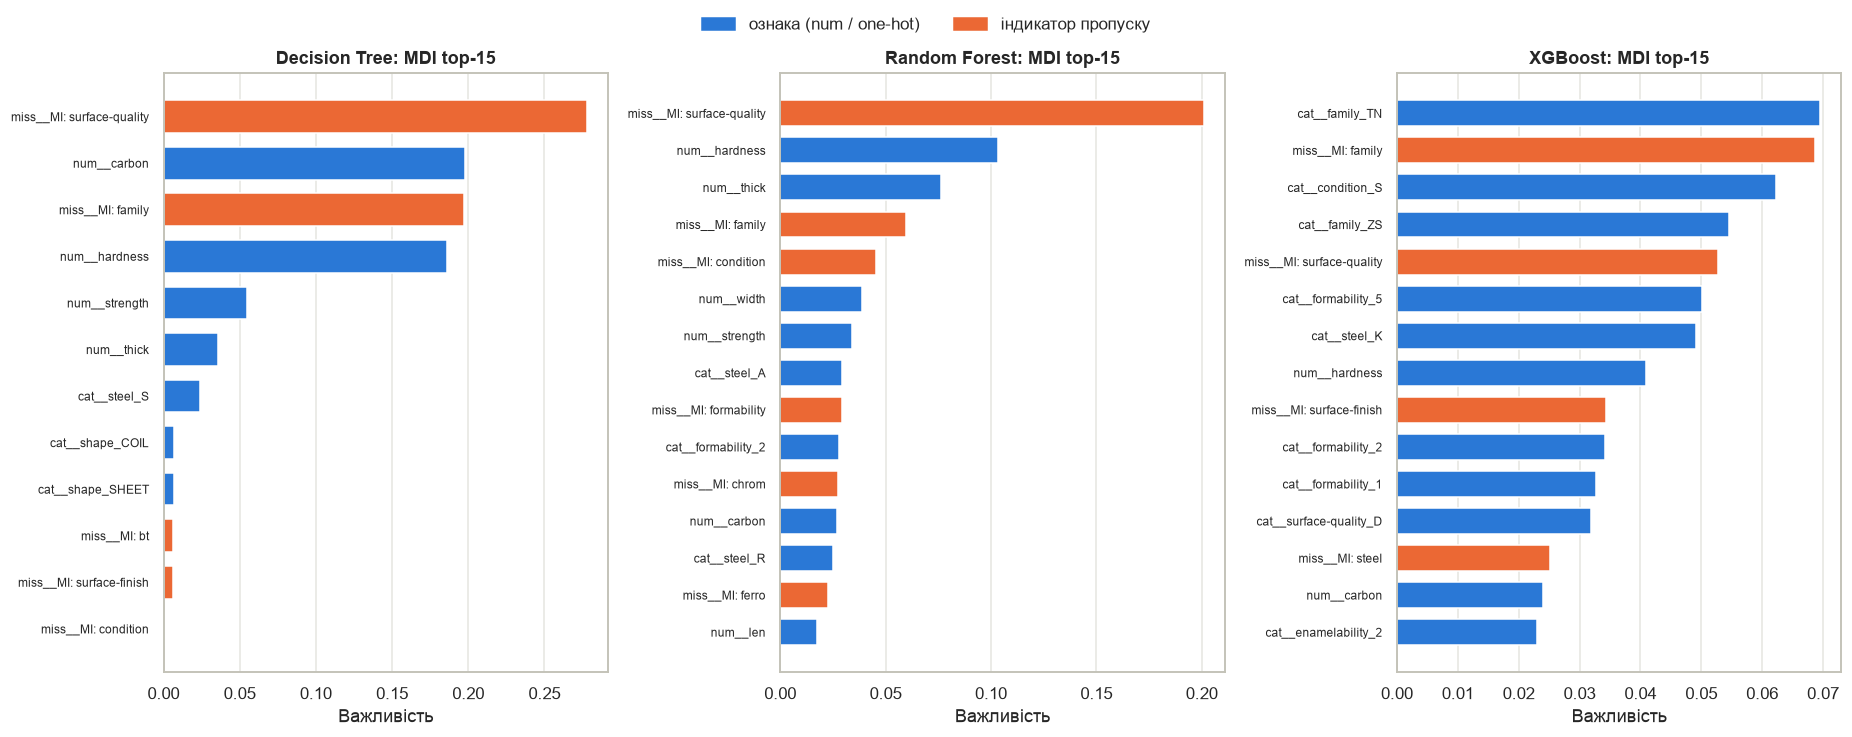

,індикаторів у top-15 (MDI > 0),частка MDI індикаторів (усього),індикатори в top-15
Decision Tree,5,0.488,"surface-quality, family, bt, surface-finish, condition"
Random Forest,6,0.483,"surface-quality, family, condition, formability, chrom, ferro"
XGBoost,4,0.346,"family, surface-quality, surface-finish, steel"


In [20]:
mdi_tables = {}
fig, axes = plt.subplots(1, 3, figsize=(17, 6.5))
for ax, name in zip(axes, MODEL_NAMES):
    model = final_models[name]
    names = model.named_steps["prep"].get_feature_names_out()
    importances = pd.Series(model.named_steps["clf"].feature_importances_, index=names).sort_values(ascending=False)
    mdi_tables[name] = importances
    top = importances[importances > 0].head(15)[::-1]
    colors = [COLORS["orange"] if label.startswith("miss__") else COLORS["blue"] for label in top.index]
    ax.barh([label.replace("missingindicator_", "MI: ") for label in top.index], top.values, color=colors, height=0.7)
    ax.set(title=f"{MODEL_TITLES[name]}: MDI top-15", xlabel="Важливість")
    ax.grid(axis="y", visible=False)
    ax.tick_params(axis="y", labelsize=8)
fig.legend(handles=[matplotlib.patches.Patch(color=COLORS["blue"], label="ознака (num / one-hot)"),
                    matplotlib.patches.Patch(color=COLORS["orange"], label="індикатор пропуску")],
           loc="upper center", ncol=2, frameon=False, bbox_to_anchor=(0.5, 1.04))
plt.tight_layout()
plt.show()

indicator_summary = pd.DataFrame.from_dict(orient="index", data={
    MODEL_TITLES[name]: {
        "індикаторів у top-15 (MDI > 0)": sum(label.startswith("miss__")
                                             for label in mdi_tables[name][mdi_tables[name] > 0].head(15).index),
        "частка MDI індикаторів (усього)": round(mdi_tables[name][mdi_tables[name].index.str.startswith("miss__")].sum(), 3),
        "індикатори в top-15": ", ".join(
            label.replace("miss__missingindicator_", "")
            for label in mdi_tables[name][mdi_tables[name] > 0].head(15).index if label.startswith("miss__")),
    }
    for name in MODEL_NAMES
})
display(indicator_summary)

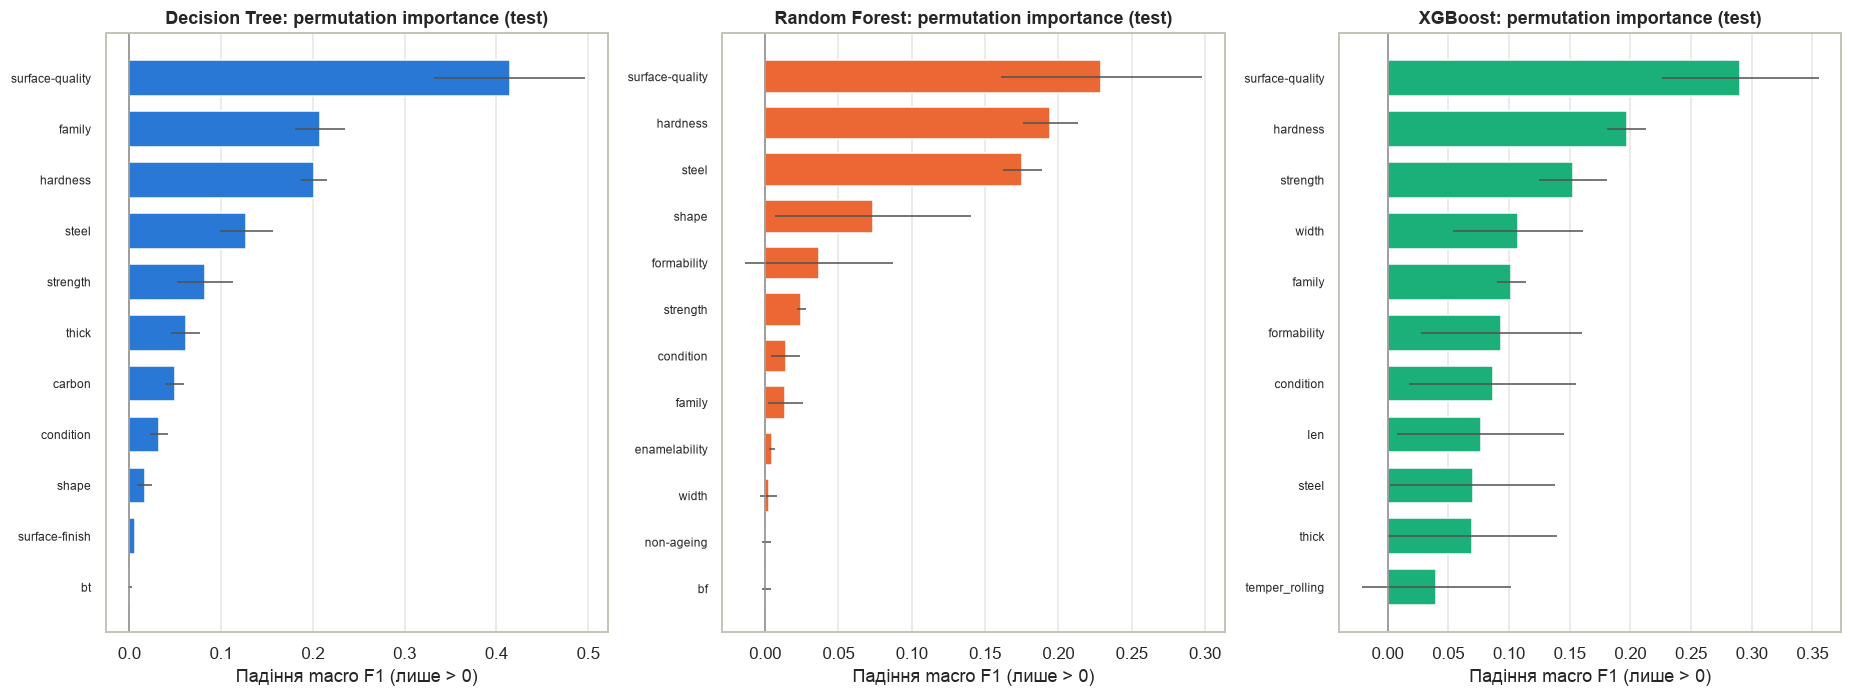

MDI агреговано до початкових ознак (сума по one-hot стовпцях та індикатору ознаки):

,Spearman ρ (MDI vs perm),спільних у top-5,top-5 MDI,top-5 permutation,ознак із perm > 0
Decision Tree,0.986,4,"surface-quality, carbon, family, hardness, strength","surface-quality, family, hardness, steel, strength",11
Random Forest,0.704,4,"surface-quality, hardness, steel, family, formability","surface-quality, hardness, steel, shape, formability",12
XGBoost,0.435,2,"family, formability, steel, surface-quality, condition","surface-quality, hardness, strength, width, family",11


In [21]:
permutation_tables = {}
fig, axes = plt.subplots(1, 3, figsize=(17, 6.5))
for ax, name in zip(axes, MODEL_NAMES):
    result = permutation_importance(
        final_models[name], X_test, y_test, scoring="f1_macro", n_repeats=20, random_state=SEED
    )
    table = pd.DataFrame({"mean": result.importances_mean, "std": result.importances_std},
                         index=X_test.columns).sort_values("mean", ascending=False)
    permutation_tables[name] = table
    top = table[table["mean"] > 0].head(15)[::-1]
    ax.barh(top.index, top["mean"], xerr=top["std"], color=MODEL_COLORS[name], height=0.7,
            error_kw={"ecolor": "#52514e", "elinewidth": 1})
    ax.axvline(0, color=COLORS["muted"], linewidth=1)
    ax.set(title=f"{MODEL_TITLES[name]}: permutation importance (test)", xlabel="Падіння macro F1 (лише > 0)")
    ax.grid(axis="y", visible=False)
    ax.tick_params(axis="y", labelsize=8)
plt.tight_layout()
plt.show()


def original_feature(processed_name, columns):
    block, _, rest = processed_name.partition("__")
    if block == "miss":
        return rest.replace("missingindicator_", "", 1)
    if block == "num":
        return rest
    return max((column for column in columns if rest.startswith(f"{column}_")), key=len)


agreement_rows = {}
for name in MODEL_NAMES:
    mdi_by_original = mdi_tables[name].groupby(
        [original_feature(label, X_train.columns) for label in mdi_tables[name].index]).sum()
    joined = pd.concat([mdi_by_original.rename("MDI"), permutation_tables[name]["mean"].rename("perm")],
                       axis=1).fillna(0)
    agreement_rows[MODEL_TITLES[name]] = {
        "Spearman ρ (MDI vs perm)": round(stats.spearmanr(joined["MDI"], joined["perm"]).statistic, 3),
        "спільних у top-5": len(set(joined["MDI"].nlargest(5).index) & set(joined["perm"].nlargest(5).index)),
        "top-5 MDI": ", ".join(joined["MDI"].nlargest(5).index),
        "top-5 permutation": ", ".join(joined["perm"].nlargest(5).index),
        "ознак із perm > 0": int((permutation_tables[name]["mean"] > 0).sum()),
    }
display(Markdown("MDI агреговано до початкових ознак (сума по one-hot стовпцях та індикатору ознаки):"))
display(pd.DataFrame.from_dict(agreement_rows, orient="index"))

**Відповіді на запитання.**

*Чи потрапили індикатори пропусків до top-15 за MDI?* Так, у всіх трьох моделей: 5 у DT, 6 у RF і 4 у XGBoost. У DT і RF найважливіша ознака взагалі — `missingindicator_surface-quality`, у XGBoost на другому місці `missingindicator_family`. Сумарно індикатори забирають 49% MDI у DT, 48% у RF і 35% у XGBoost. Це узгоджується з п. 3.1: пропуск `surface-quality` має найсильніший зв'язок із класом (V Крамера 0.74), і моделі використовують саме факт пропуску, а не імпутоване значення. Це також пояснює значущий приріст якості від варіанту A до B.

*Наскільки узгоджуються MDI і permutation importance?* Для DT майже повністю (Spearman ρ = 0.99), для RF помірно (0.70), для XGBoost слабко (0.44). Водночас `surface-quality` і `hardness` входять у top-3 permutation importance у всіх трьох моделей.

Причини розбіжностей такі. MDI рахується на train і показує, наскільки ознака зменшує неоднорідність у розщепленнях, а permutation — на тесті й показує, наскільки від ознаки залежить якість. Крім того, MDI зміщена на користь ознак із багатьма унікальними значеннями (Strobl et al., 2007). Неперервні `carbon`, `thick`, `width` мають десятки можливих порогів, і дерево знаходить «корисні» розщеплення навіть на шумі. Наприклад, `carbon` — друга ознака за MDI у DT, але лише сьома за permutation. Нарешті, у XGBoost MDI — це gain, який розподіляється між взаємозамінними стовпцями: `family_TN`, `family_ZS` та індикатор `family` кодують майже одне й те саме, тож важливість розмазується між ними.

*Чому важливість однієї ознаки відрізняється між DT, RF і XGB?* Одне дерево жадібно бере найкращу ознаку в корені, і вона отримує левову частку MDI. RF через `max_features='sqrt'` змушує дерева використовувати різні ознаки, тому важливість розподіляється між взаємозамінними `hardness`, `thick`, `steel`. XGBoost будує дерева послідовно: коли перші дерева «вичерпали» сильну ознаку, наступні виправляють залишки за іншими. За наявності дублюючих ознак (`family` і її індикатор, `condition` і `formability`) кожна модель обирає «свого» представника, тому важливості на рівні окремих ознак не варто порівнювати буквально.

## 3.8 Аналіз розбіжностей між моделями

Об'єкт розбіжності — той, на якому прогнози трьох фінальних моделей не всі однакові. Спочатку шукаємо такі об'єкти в тестовій вибірці. Якщо їх менше трьох, доповнюємо **out-of-fold** прогнозами на train (`cross_val_predict` з тими самими найкращими параметрами) і явно позначаємо джерело.

In [22]:
test_frame = pd.DataFrame({MODEL_TITLES[name]: class_names[test_predictions[name]] for name in MODEL_NAMES},
                          index=X_test.index)
test_frame.insert(0, "справжній клас", class_names[y_test])
test_frame.insert(0, "джерело", "test")
disagreements = test_frame[test_frame[[MODEL_TITLES[n] for n in MODEL_NAMES]].nunique(axis=1) > 1]
print(f"Розбіжностей у test: {len(disagreements)}")

if len(disagreements) < 3:
    oof_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
    oof_predictions = {
        name: cross_val_predict(build_pipeline(name, True, final_studies[name].best_params),
                                X_train, y_train, cv=oof_cv)
        for name in MODEL_NAMES
    }
    oof_frame = pd.DataFrame({MODEL_TITLES[name]: class_names[oof_predictions[name]] for name in MODEL_NAMES},
                             index=X_train.index)
    oof_frame.insert(0, "справжній клас", class_names[y_train])
    oof_frame.insert(0, "джерело", "train (OOF)")
    oof_disagreements = oof_frame[oof_frame[[MODEL_TITLES[n] for n in MODEL_NAMES]].nunique(axis=1) > 1]
    print(f"Розбіжностей у train за OOF-прогнозами: {len(oof_disagreements)}")
    disagreements = pd.concat([disagreements, oof_disagreements])

disagreement_table = disagreements.copy()
disagreement_table.index = [f"#{index}" for index in disagreement_table.index]
disagreement_table.index.name = "об'єкт (індекс у датасеті)"
display(Markdown("**Таблиця 7.** Об'єкти розбіжностей між прогнозами моделей"))
display(disagreement_table)

Розбіжностей у test: 1


Розбіжностей у train за OOF-прогнозами: 7


**Таблиця 7.** Об'єкти розбіжностей між прогнозами моделей

,джерело,справжній клас,Decision Tree,Random Forest,XGBoost
об'єкт (індекс у датасеті),,,,,
#746,test,3,2,3,2
#90,train (OOF),U,U,3,3
#585,train (OOF),3,2,3,3
#896,train (OOF),U,3,U,U
#110,train (OOF),3,2,3,3
#17,train (OOF),U,3,U,U
#16,train (OOF),U,U,3,3
#288,train (OOF),1,1,1,3


### Детальний аналіз одного об'єкта розбіжності

Беремо об'єкт розбіжності з тестової вибірки (якщо такий є), щоб усі три фінальні моделі пояснювали прогноз на даних, яких не бачили під час навчання.

In [23]:
test_disagreements = disagreements[disagreements["джерело"] == "test"]
focus_index = (test_disagreements if len(test_disagreements) else disagreements).index[0]
focus_row = X.loc[[focus_index]]
print(f"Об'єкт #{focus_index}, джерело: {disagreements.loc[focus_index, 'джерело']}, "
      f"справжній клас: {disagreements.loc[focus_index, 'справжній клас']}")

prep_reference = final_models[best_name].named_steps["prep"]
numeric_fill = pd.Series(prep_reference.named_transformers_["num"].statistics_,
                         index=prep_reference.transformers_[0][2])
categorical_fill = pd.Series(prep_reference.named_transformers_["cat"].named_steps["impute"].statistics_,
                             index=prep_reference.transformers_[1][2])
fill_values = pd.concat([numeric_fill, categorical_fill])

raw_values = focus_row.iloc[0]
feature_view = pd.DataFrame({
    "початкове значення": raw_values.astype(object).where(raw_values.notna(), "NaN"),
    "пропуск": raw_values.isna().map({True: "так", False: ""}),
    "після імпутації": [fill_values.get(column, "—") if pd.isna(value) else value
                        for column, value in raw_values.items()],
})
display(feature_view)
print(f"Пропущено {raw_values.isna().sum()} з {len(raw_values)} ознак")

Об'єкт #746, джерело: test, справжній клас: 3


,початкове значення,пропуск,після імпутації
family,NaN,так,TN
steel,V,,V
carbon,0,,0
hardness,0,,0
temper_rolling,NaN,так,T
condition,S,,S
formability,2,,2
strength,0,,0
non-ageing,NaN,так,N
surface-finish,NaN,так,P


Пропущено 19 з 31 ознак


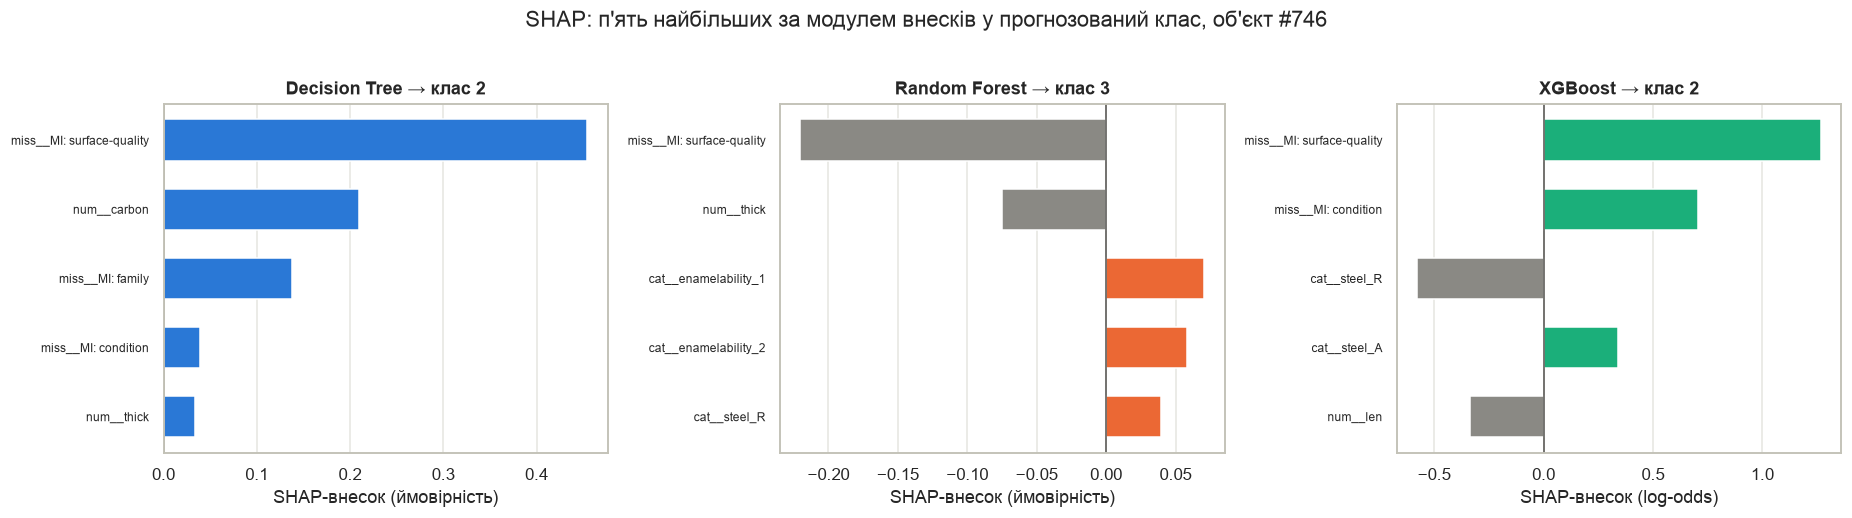

Ймовірності `predict_proba` трьох моделей для цього об'єкта:

,1,2,3,5,U
Decision Tree,0.000,1.000,0.000,0.00,0.000
Random Forest,0.007,0.380,0.613,0.00,0.000
XGBoost,0.022,0.744,0.220,0.01,0.004


Top-5 SHAP-ознак для прогнозованого кожною моделлю класу:

,Decision Tree,Random Forest,XGBoost
#1,miss__missingindicator_surface-quality (+0.454),miss__missingindicator_surface-quality (-0.220),miss__missingindicator_surface-quality (+1.269)
#2,num__carbon (+0.210),num__thick (-0.075),miss__missingindicator_condition (+0.705)
#3,miss__missingindicator_family (+0.138),cat__enamelability_1 (+0.071),cat__steel_R (-0.578)
#4,miss__missingindicator_condition (+0.040),cat__enamelability_2 (+0.058),cat__steel_A (+0.339)
#5,num__thick (+0.033),cat__steel_R (+0.039),num__len (-0.336)


In [24]:
probability_rows = {}
shap_tops = {}
fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))
for ax, name in zip(axes, MODEL_NAMES):
    model = final_models[name]
    prep, clf = model.named_steps["prep"], model.named_steps["clf"]
    processed = prep.transform(focus_row)
    feature_names = prep.get_feature_names_out()
    probabilities = model.predict_proba(focus_row)[0]
    predicted = int(np.argmax(probabilities))
    probability_rows[MODEL_TITLES[name]] = dict(zip(class_names, np.round(probabilities, 3)))

    explanation = shap.TreeExplainer(clf).shap_values(processed)
    values = explanation[predicted][0] if isinstance(explanation, list) else np.asarray(explanation)[0, :, predicted]
    contributions = pd.Series(values, index=feature_names)
    top = contributions.reindex(contributions.abs().sort_values(ascending=False).index).head(5)
    shap_tops[MODEL_TITLES[name]] = [f"{label} ({value:+.3f})" for label, value in top.items()]

    shown = top[::-1]
    ax.barh([label.replace("missingindicator_", "MI: ") for label in shown.index], shown.values,
            color=[MODEL_COLORS[name] if value >= 0 else COLORS["muted"] for value in shown.values], height=0.6)
    ax.axvline(0, color="#52514e", linewidth=1)
    unit = "log-odds" if name == "XGB" else "ймовірність"
    ax.set(title=f"{MODEL_TITLES[name]} → клас {class_names[predicted]}", xlabel=f"SHAP-внесок ({unit})")
    ax.grid(axis="y", visible=False)
    ax.tick_params(axis="y", labelsize=8)
fig.suptitle(f"SHAP: п'ять найбільших за модулем внесків у прогнозований клас, об'єкт #{focus_index}", y=1.02)
plt.tight_layout()
plt.show()

display(Markdown("Ймовірності `predict_proba` трьох моделей для цього об'єкта:"))
display(pd.DataFrame(probability_rows).T)
display(Markdown("Top-5 SHAP-ознак для прогнозованого кожною моделлю класу:"))
display(pd.DataFrame(shap_tops, index=[f"#{i}" for i in range(1, 6)]))

**Аналіз розбіжностей.** У тесті розбіжність лише одна (#746): ефект стелі означає, що три моделі погоджуються на 179 із 180 об'єктів. Тому табл. 7 доповнено сімома об'єктами з train за out-of-fold прогнозами (позначка «train (OOF)»). У них повторюються два сценарії: клас `U` плутають із `3` (#16, #17, #90, #896), а клас `3` Decision Tree відносить до `2` (#110, #585). Ще один об'єкт — #288 класу `1`, який XGBoost відносить до `3`. В усіх випадках класи розрізняються передусім наявністю або відсутністю окремих ознак.

**Об'єкт #746** (справжній клас `3`): DT → `2`, RF → `3`, XGBoost → `2`.

1. *Роль пропусків та імпутації.* В об'єкта пропущено 19 з 31 ознак, серед них `surface-quality` і `family`. Імпутація заповнила їх модами `E` і `TN`, тобто після неї об'єкт має «типові» значення. Але індикатор пропуску `surface-quality` дорівнює 1, а пропуск цієї ознаки — сильний маркер класу `2`: він трапляється у 89 з 99 об'єктів класу `2` і лише у 80 з 684 об'єктів класу `3`. Тому в усіх трьох моделях саме `missingindicator_surface-quality` має найбільший за модулем SHAP-внесок. У DT і XGBoost він штовхає прогноз до `2` (+0.45 ймовірності та +1.27 log-odds), у RF — від класу `3` (−0.22). Самі імпутовані значення `E` і `TN` серед головних внесків не фігурують.
2. *Жорсткі пороги проти усереднення.* Дерево рішень проводить об'єкт одним шляхом жорстких порогів; за SHAP вирішальними на ньому були індикатор `surface-quality`, `carbon` та індикатор `family`, і шлях закінчився в чистому листі класу `2`. Звідси ймовірність 1.000: окреме дерево не вміє «сумніватися». RF усереднює 150 дерев, побудованих на різних підмножинах ознак. Частина з них розщеплює за `enamelability` і `steel`, що вказують на `3`, і в сумі клас `3` перемагає (0.613 проти 0.380). XGBoost підсумовує внески послідовних дерев у log-odds. Великі внески індикаторів `surface-quality` (+1.27) і `condition` (+0.71) переважують аргументи на користь `3` від `steel` і `len`, тож модель обирає `2` (0.744).
3. *Близькість до межі класів.* Ймовірності RF (0.61 / 0.38 для `3` / `2`) і XGBoost (0.22 / 0.74) показують, що об'єкт лежить біля межі `2` / `3`. Він має «підпис пропусків» класу `2`, але решту параметрів, характерних для класу `3`. Розбіжність виникає не через помилку реалізації: ансамблі по-різному зважують суперечливі сигнали, а одне дерево бачить лише один із них.

## Висновок

1. За вкладеною CV найкращий macro F1 мають XGBoost (0.9868 ± 0.0138) і Random Forest (0.9861 ± 0.0101), Decision Tree трохи позаду (0.9782 ± 0.0146). Перевага не є статистично значущою: дві найкращі моделі з типовими параметрами (RF і DT) не розрізняються за тестом Наде–Бенжіо ($p = 0.89$), а на тесті всі три моделі розділяють лише 1–2 об'єкти.
2. Індикатори пропусків — головний чинник якості: вони підвищують macro F1 на 0.055–0.065 для всіх трьох моделей, і ця різниця значуща ($p \le 0.043$). Це повністю узгоджується з аналізом механізму пропусків (пропуски пов'язані з класом, V Крамера до 0.74) і з важливостями: на індикатори припадає 35–49% MDI, а `missingindicator_surface-quality` — найважливіша ознака DT і RF.
3. `best_value` виявився **нижчим** за вкладену CV (0.89–0.92 проти 0.98–0.99), бо в 3-блочному розбитті обидва об'єкти рідкісного підтипу класу `1` потрапили в один блок, хоча саме по собі зміщення максимуму (+0.013–0.037 над медіаною спроб) нікуди не зникло. Отже, на таких даних `best_value` ненадійний в обидва боки, і якість потрібно подавати за вкладеною CV.
4. Найбільший приріст після оптимізації має XGBoost (0.971 з типовими параметрами → 0.987 у вкладеній CV, хоча схеми CV дещо різні): менший learning rate (0.043) і 371 дерево роблять ансамбль стабільнішим на рідкісному класі, тоді як для DT і RF Optuna майже повернулася до типових параметрів (`min_samples_leaf = 1`, `class_weight = None`), бо вони вже оптимальні.
5. Найскладніший клас — `1` (лише 8 об'єктів, серед них нетиповий #24 зі `strength = 0`, якого пропускають усі моделі), а також пара `3` ↔ `2`, де пропуск `surface-quality` характерний для класу `2`. Аналіз розбіжностей показав, що моделі розходяться саме на таких межових об'єктах: «підпис пропусків» одного класу поєднується в них із параметрами іншого, і одне дерево впевнено помиляється, а ансамбль вагається або виправляє помилку.
6. Для практичного використання доцільно обрати **Random Forest**: якість на рівні XGBoost, найменше std у вкладеній CV (0.010), одна помилка на тесті, стійкість до гіперпараметрів і вдвічі дешевший підбір (≈ 125 с проти ≈ 240 с). Якщо пріоритетом є прозорість правил, прийнятний і Decision Tree (macro F1 0.978) — ціною меншої стабільності на межових об'єктах.

## Контрольні питання

**1. Random Forest vs дерево рішень: зміщення і дисперсія.** Глибоке дерево має мале зміщення, але велику дисперсію: невелика зміна вибірки змінює верхні розщеплення, а з ними й усю структуру. RF усереднює $B$ дерев, побудованих на бутстреп-вибірках. Для корельованих дерев дисперсія середнього дорівнює $\rho\sigma^2 + \frac{1-\rho}{B}\sigma^2$: другий доданок зникає зі зростанням $B$, а перший обмежується кореляцією $\rho$. Тому RF додатково **декорелює** дерева випадковим вибором підмножини ознак (`max_features`) у кожному вузлі. Зміщення лишається приблизно як в окремого дерева, а дисперсія різко падає.

**2. Бустинг vs беггінг.** Беггінг будує незалежні моделі паралельно й усереднює їх — це зменшує дисперсію. Бустинг будує моделі послідовно: кожне нове дерево апроксимує антиградієнт функції втрат ансамблю, тобто виправляє помилки попередніх, — це зменшує зміщення. Зі зростанням кількості дерев до перенавчання схильніший **бустинг**: кожне дерево ще більше підганяє залишки, зокрема шум. У RF додавання дерев лише стабілізує середнє, і помилка виходить на плато. Тому для бустингу важливі `learning_rate`, глибина, `subsample` і рання зупинка.

**3. Macro F1 і balanced accuracy при дисбалансі.** Accuracy домінує клас `3` (76%): модель, що завжди відповідає «3», має accuracy 0.76, хоча повністю ігнорує 4 класи. Balanced accuracy — середній recall по класах, macro F1 — середнє F1 по класах; обидві дають кожному класу однакову вагу, тому провал на рідкісному класі `1` помітний. Weighted F1 зважує F1 класів за їхньою частотою й знову наближається до accuracy, приховуючи рідкісні класи.

**4. MCAR, MAR, MNAR.** MCAR — пропуск не залежить ні від чого. MAR — залежить лише від спостережуваних ознак. MNAR — залежить від самого невідомого значення або неспостережуваних чинників. Індикатори пропусків найкорисніші, коли пропуск **сам несе інформацію про ціль** (MNAR і структурні пропуски, як тут): після імпутації ця інформація зникає, а індикатор її зберігає. За MCAR індикатор — шум. Однозначно відрізнити MAR від MNAR за даними **неможливо**: для цього потрібні значення, яких якраз немає. Таблиці спряженості показують лише зв'язок пропуску з класом, а не його причину.

**5. Витік даних в імпутації та оптимізації.** (а) `fit_transform` імпутера, кодувальника чи `MissingIndicator` на всьому датасеті до поділу або до CV: медіани, моди, набір категорій і список ознак з пропусками «бачать» валідацію. (б) Передача в Optuna заздалегідь обробленого `X_train_proc`. (в) Використання тесту в цільовій функції або для вибору моделі. Запобігання: уся обробка — всередині `Pipeline`, у CV і Optuna передається сирий `X`, тест відкривається один раз для фінальної оцінки.

**6. Чому `best_value` оптимістично зміщена.** Optuna обирає максимум із 30 зашумлених оцінок CV. Математичне сподівання максимуму більше за сподівання оцінки обраної конфігурації (selection bias / winner's curse), до того ж гіперпараметри підлаштовуються під ті самі блоки. У вкладеній CV зовнішній валідаційний блок не бере участі в підборі. Отже, у зовнішньому циклі оцінюється не конкретна модель, а **вся процедура** «Optuna-підбір на тренувальній частині + навчання з найкращими параметрами».

**7. Чому звичайний парний t-тест не підходить.** Тренувальні частини різних блоків CV перетинаються на ~75%, тому оцінки на блоках корельовані. Звичайний t-тест вважає їх незалежними, недооцінює дисперсію середньої різниці й занадто часто бачить «значущі» відмінності. Наде–Бенжіо множать дисперсію на $\left(\frac{1}{kr} + \frac{n_\text{test}}{n_\text{train}}\right)$ замість $\frac{1}{kr}$. Доданок $\frac{n_\text{test}}{n_\text{train}}$ компенсує кореляцію між блоками. У табл. 5 для порівняння наведено обидва p-значення.

**8. MDI vs permutation importance.** MDI — сумарне зменшення Gini-неоднорідності від розщеплень за ознакою, обчислене на **тренувальних** даних. Воно дешеве, але зміщене на користь ознак з багатьма унікальними значеннями (більше можливих порогів — більше шансів випадково зменшити неоднорідність) і не відображає узагальнення. Permutation importance — падіння метрики на відкладених даних після перемішування ознаки: показує реальний внесок у якість, але дорожча. Корельовані ознаки MDI ділять між собою (важливість «розмазується»), а permutation importance для кожної з них занижує, бо модель бере ту саму інформацію з корельованого партнера.

**9. SHAP.** SHAP-значення — вектори Шеплі з теорії ігор: середній граничний внесок ознаки в прогноз по всіх можливих коаліціях інших ознак. Властивість **адитивності (local accuracy)**: $f(x) = \mathbb{E}[f(X)] + \sum_j \phi_j(x)$, тобто внески точно складаються в прогноз (для XGBoost — у log-odds класу). Локальне пояснення описує, чому модель дала саме цей прогноз для одного об'єкта. Глобальна важливість (MDI, permutation або середнє $|\phi_j|$) усереднює поведінку на всіх об'єктах і може приховувати локально вирішальні, але рідкісні ознаки.

**10. Нативна обробка пропусків у XGBoost.** Sparsity-aware split finding: для кожного розщеплення алгоритм перебирає пороги лише за спостережуваними значеннями, а потім пробує надіслати всі об'єкти з пропуском ліворуч і праворуч і запам'ятовує **напрям за замовчуванням** з більшим приростом функції втрат. Пропуски не заповнюються, а маршрутизуються туди, де вони найкраще пояснюють ціль. Фактично модель сама вивчає інформативність пропуску, як індикатори з варіанту B.

**11. Переваги Optuna.** TPE будує ймовірнісні моделі «хороших» і «поганих» конфігурацій ($l(x)$ та $g(x)$) і пропонує точки з великим $l(x)/g(x)$. Тобто підбір адаптивний: використовує результати попередніх спроб, на відміну від повного перебору (`GridSearchCV`, експоненційний у кількості параметрів) і незалежних випадкових спроб (`RandomizedSearchCV`). Прунінг зупиняє безперспективні спроби за проміжними значеннями, а define-by-run API дозволяє умовні простори пошуку (як тут — різні параметри для DT/RF/XGB). Є вбудовані візуалізації історії та важливості гіперпараметрів (fANOVA).